# Lüga · EDA de oportunidades

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/montesquieu891/precio-entorno-caba/blob/main/notebooks/eda_oportunidades.ipynb)

**Pregunta guía:** ¿qué puede aprender la app de los datos para que la persona decida mejor y más rápido?
El flujo del producto es *preferencias → comparación de barrios → búsqueda guardada → alerta*. Cada sección
termina con una propuesta concreta para alguno de esos pasos.

**Qué es una "oportunidad" en este notebook.** No es una ganga ni una tasación. Es una de tres cosas, todas
sobre **precios de publicación**:

1. **Aviso por debajo de sus comparables:** pide menos USD/m² que avisos parecidos (barrio, tamaño, ambientes,
   ubicación) y la diferencia supera el error típico del modelo.
2. **Barrio alternativo:** un barrio con un entorno parecido al que la persona quiere, a menor USD/m².
3. **Presupuesto que rinde:** el punto donde un pequeño aumento del presupuesto abre muchas opciones nuevas.

**Fuentes.** Catálogo autorizado de avisos vigentes (RE/MAX, Century 21, Migliorisi, Clarín y Zonaprop, capturas
del 7 al 9 de noviembre de 2026) y Mapa del Delito de CABA (hechos registrados por barrio, 2024–2025). Capas de
entorno de BA Data y OpenStreetMap.

**Límites que hay que tener presentes en todo el notebook:**
- Son precios publicados, no de cierre. No hay fotos ni descripción: la antigüedad y el estado solo los publican
  algunas fuentes (sección 3 bis).
- Hay una sola captura: no se puede medir tiempo publicado ni bajas de precio.
- Zonaprop trae hasta 50 avisos por barrio: la muestra está **balanceada por barrio**, no es proporcional al mercado.
- Las coordenadas son aproximadas (ninguna fuente declara la precisión).
- Los delitos son **hechos registrados**, con su período y su unidad geográfica (barrio). Se muestran como contexto.

## 0. Carga de datos

El paquete `eda_bundle.zip` se genera en la computadora del proyecto con

```powershell
python -m precio_entorno.eda_colab
```

y queda en `data/processed/eda-colab/` (fuera de Git). En Colab, la celda siguiente lo busca en Drive
(`MyDrive/precio-entorno-caba/eda_bundle.zip`) y, si no está, pide subirlo.

In [1]:
import io, json, zipfile, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection

warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

CANDIDATOS = [Path('eda_bundle.zip'),
              Path('../data/processed/eda-colab/eda_bundle.zip'),
              Path('data/processed/eda-colab/eda_bundle.zip'),
              Path('/content/drive/MyDrive/precio-entorno-caba/eda_bundle.zip')]

try:
    import google.colab  # noqa: F401
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

if EN_COLAB and not any(p.exists() for p in CANDIDATOS):
    try:
        from google.colab import drive
        drive.mount('/content/drive')
    except Exception as e:
        print('Sin Drive:', e)

BUNDLE = next((p for p in CANDIDATOS if p.exists()), None)
if BUNDLE is None and EN_COLAB:
    from google.colab import files
    subido = files.upload()
    BUNDLE = Path(next(iter(subido)))
if BUNDLE is None:
    raise FileNotFoundError('No encuentro eda_bundle.zip. Generalo con: python -m precio_entorno.eda_colab')

z = zipfile.ZipFile(BUNDLE)
venta = pd.read_csv(z.open('venta.csv'))
alquiler = pd.read_csv(z.open('alquiler.csv'))
entorno = json.load(z.open('entorno/resumen.json'))
geo = json.load(z.open('entorno/barrios.geojson'))
delitos_anio = pd.read_csv(z.open('delitos/barrio_anio.csv'))
delitos_franja = pd.read_csv(z.open('delitos/franja_categoria.csv'), dtype={'franja': str})
meta = json.load(z.open('meta.json'))

SALIDA = Path('salidas_eda') if EN_COLAB else BUNDLE.parent / 'salidas'
SALIDA.mkdir(exist_ok=True)

print(meta['aviso'])
print(f"Venta: {len(venta):,} avisos · Alquiler: {len(alquiler):,} avisos · Fechas de captura: {', '.join(meta['captura'])}".replace(',', '.', 2))

Precios de publicación, no tasaciones ni precios de cierre. Datos reales del catálogo autorizado.
Venta: 3.806 avisos · Alquiler: 3.272 avisos · Fechas de captura: 2026-11-07, 2026-11-08, 2026-11-09


In [2]:
# Estilo: paleta de la app (jacarandá como acento, grises de vereda y asfalto).
JACARANDA, ASFALTO, CORDON, GRIS = '#6A4FB3', '#1E2A32', '#CBD0CC', '#8A928D'
AZUL, NARANJA, AQUA = '#2a78d6', '#eb6834', '#1baf7a'   # categóricos validados (3 primeros)
plt.rcParams.update({
    'figure.dpi': 110, 'figure.facecolor': 'white', 'axes.facecolor': 'white',
    'axes.edgecolor': CORDON, 'axes.labelcolor': ASFALTO, 'text.color': ASFALTO,
    'xtick.color': GRIS, 'ytick.color': GRIS, 'axes.grid': True, 'grid.color': '#ECEEEB',
    'grid.linewidth': .8, 'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titleweight': 'semibold', 'axes.titlesize': 12, 'axes.titlelocation': 'left',
    'font.size': 10, 'legend.frameon': False,
})
usd = mtick.FuncFormatter(lambda x, _: f'{x:,.0f}'.replace(',', '.'))
pct = mtick.PercentFormatter(1.0, decimals=0)


def miles(x):
    return f'{x:,.0f}'.replace(',', '.')


def poligonos(g):
    return g['coordinates'] if g['type'] == 'MultiPolygon' else [g['coordinates']]


def mapa_barrios(valores, titulo, cmap='Purples', fmt=miles, ax=None, etiquetas=6, centro=None, lim=None):
    # Coropleta simple con matplotlib (sin geopandas): valores es una Serie indexada por barrio.
    ax = ax or plt.subplots(figsize=(7, 7))[1]
    parches, datos = [], []
    piezas = [(f['properties']['barrio'], p) for f in geo['features'] for p in poligonos(f['geometry'])]
    for nombre, p in piezas:
        parches.append(MplPolygon(np.array(p[0]), closed=True))
        datos.append(valores.get(nombre, np.nan))
    datos = np.array(datos, dtype=float)
    col = PatchCollection(parches, cmap=cmap, edgecolor='white', linewidth=.6)
    col.set_array(np.ma.masked_invalid(datos))
    if centro is not None:
        lim = lim or np.nanmax(np.abs(datos - centro))
        col.set_clim(centro - lim, centro + lim)   # los valores fuera de ±lim quedan con el color extremo
    col.cmap.set_bad('#F3F4F1')
    ax.add_collection(col)
    ax.autoscale_view(); ax.set_aspect(1.2); ax.axis('off')
    ax.set_title(titulo)
    cb = plt.colorbar(col, ax=ax, shrink=.6, format=mtick.FuncFormatter(lambda x, _: fmt(x)))
    cb.outline.set_visible(False)
    if etiquetas:
        orden = valores.dropna().sort_values()
        for nombre in list(orden.index[:etiquetas // 2]) + list(orden.index[-(etiquetas - etiquetas // 2):]):
            f = next((f for f in geo['features'] if f['properties']['barrio'] == nombre), None)
            if f is None:
                continue
            g = f['geometry']
            anillo = np.array((g['coordinates'][0] if g['type'] == 'Polygon' else max(g['coordinates'], key=lambda p: len(p[0]))[0]))
            x, y = anillo.mean(axis=0)
            ax.annotate(nombre, (x, y), ha='center', fontsize=7.5, color=ASFALTO,
                        bbox=dict(boxstyle='round,pad=.15', fc='white', ec='none', alpha=.75))
    return ax

## 1. Qué hay en los datos y cuánto confiar en cada barrio

Antes de buscar oportunidades hay que saber dónde la muestra alcanza para comparar. Un barrio con 20 avisos
tiene una mediana mucho más inestable que uno con 200.

In [3]:
venta['ratio_cubierta'] = venta['covered_area'] / venta['total_area_m2']
venta['m2_por_ambiente'] = venta['covered_area'] / venta['rooms']
venta['con_pin'] = venta['latitude'].notna()

fuentes = venta.groupby('agency').agg(avisos=('id', 'size'), barrios=('neighborhood', 'nunique'),
                                      con_pin=('con_pin', 'mean'), con_expensas=('expenses', lambda s: s.notna().mean()),
                                      usd_m2_mediano=('precio_m2', 'median')).sort_values('avisos', ascending=False)
display(fuentes.style.format({'con_pin': '{:.0%}', 'con_expensas': '{:.0%}', 'usd_m2_mediano': '{:,.0f}'}))

faltantes = venta[['total_area_m2', 'expenses', 'latitude', 'dist_transporte_m']].isna().mean().rename('faltante')
display(faltantes.to_frame().style.format('{:.0%}'))

,avisos,barrios,con_pin,con_expensas,usd_m2_mediano
agency,,,,,
zonaprop,2272,48,99%,70%,"2,333"
remax,583,46,100%,0%,"2,500"
century21,545,42,99%,0%,"2,664"
migliorisi,388,19,0%,0%,"2,500"
clarin,18,3,0%,78%,"2,603"


,faltante
total_area_m2,2%
expenses,58%
latitude,11%
dist_transporte_m,11%


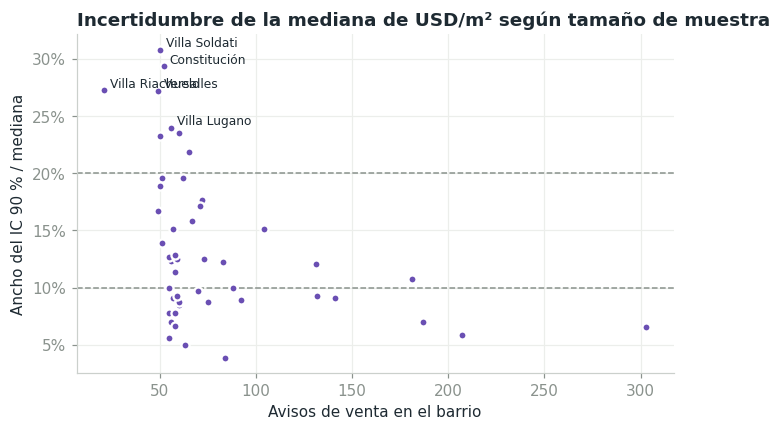

,barrios
confianza,
alta,21
media,19
baja,8


In [4]:
def ic_mediana(s, n_boot=600, seed=0):
    # Intervalo bootstrap del 90 % para la mediana de USD/m².
    rng = np.random.default_rng(seed)
    x = s.to_numpy()
    meds = np.median(rng.choice(x, size=(n_boot, len(x)), replace=True), axis=1)
    return pd.Series({'ic_bajo': np.quantile(meds, .05), 'ic_alto': np.quantile(meds, .95)})

barrios = venta.groupby('neighborhood').agg(
    avisos=('id', 'size'), fuentes=('agency', 'nunique'),
    usd_m2=('precio_m2', 'median'), p25=('precio_m2', lambda s: s.quantile(.25)), p75=('precio_m2', lambda s: s.quantile(.75)),
    precio_mediano=('price', 'median'), m2_medianos=('covered_area', 'median'))
barrios = barrios.join(venta.groupby('neighborhood')['precio_m2'].apply(ic_mediana).unstack())
barrios['ic_rel'] = (barrios['ic_alto'] - barrios['ic_bajo']) / barrios['usd_m2']
barrios['confianza'] = pd.cut(barrios['ic_rel'], [0, .10, .20, np.inf], labels=['alta', 'media', 'baja'])
barrios = barrios.sort_values('usd_m2')

fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(barrios['avisos'], barrios['ic_rel'], s=28, color=JACARANDA, edgecolor='white', linewidth=1.5, zorder=3)
for b, r in barrios.nlargest(5, 'ic_rel').iterrows():
    ax.annotate(b, (r['avisos'], r['ic_rel']), xytext=(4, 2), textcoords='offset points', fontsize=8)
ax.axhline(.10, color=GRIS, lw=1, ls='--'); ax.axhline(.20, color=GRIS, lw=1, ls='--')
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Avisos de venta en el barrio'); ax.set_ylabel('Ancho del IC 90 % / mediana')
ax.set_title('Incertidumbre de la mediana de USD/m² según tamaño de muestra')
plt.show()
display(barrios['confianza'].value_counts().to_frame('barrios'))

**Lectura.** En 21 barrios el intervalo de la mediana mide menos del 10 % de su valor, en 19 entre 10 % y 20 %,
y en 8 más del 20 %. La cantidad de avisos no lo explica todo: con unos 50 avisos cada uno, los barrios más
heterogéneos (mezcla de torres nuevas y edificios viejos) tienen intervalos mucho más anchos.

> **Para la app · comparación de barrios.** Mostrar junto a cada mediana un indicador de *confianza* (alta / media /
> baja) calculado así, y el rango P25–P75 en lugar de un único número. No es un puntaje del barrio: es una nota
> sobre cuánto informa la muestra.

## 2. Precios publicados: nivel y dispersión por barrio

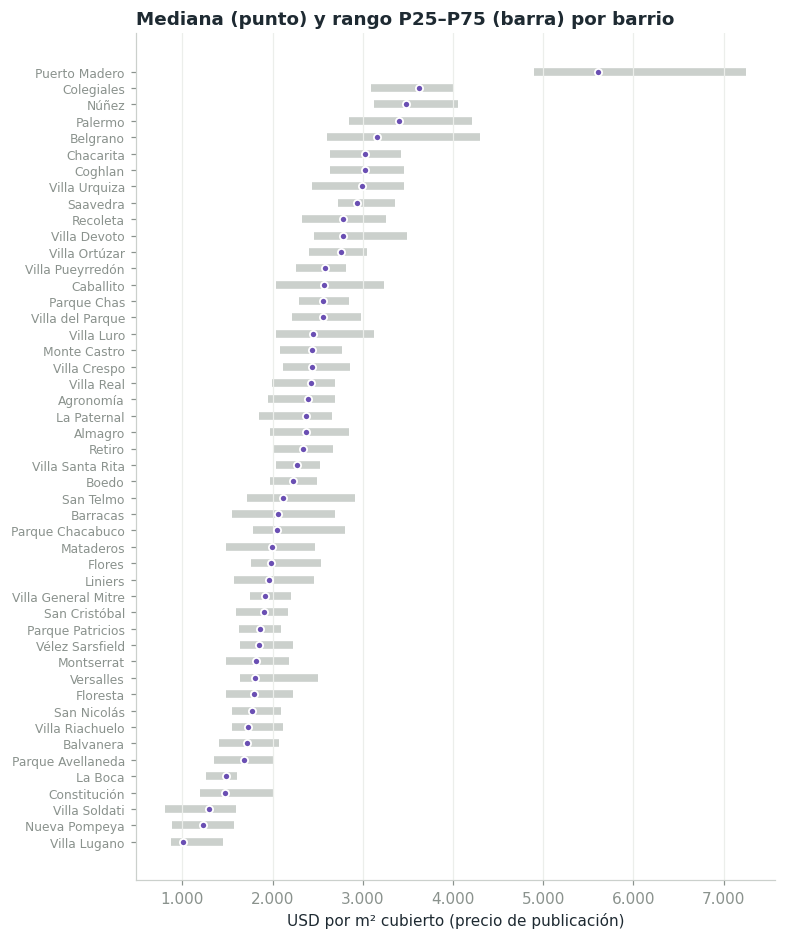

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 10))
y = np.arange(len(barrios))
ax.hlines(y, barrios['p25'], barrios['p75'], color=CORDON, lw=5, zorder=1)
ax.scatter(barrios['usd_m2'], y, color=JACARANDA, s=22, zorder=3, edgecolor='white', linewidth=1.2)
ax.set_yticks(y, barrios.index, fontsize=8)
ax.xaxis.set_major_formatter(usd)
ax.set_xlabel('USD por m² cubierto (precio de publicación)')
ax.set_title('Mediana (punto) y rango P25–P75 (barra) por barrio')
ax.grid(axis='y', visible=False)
plt.show()

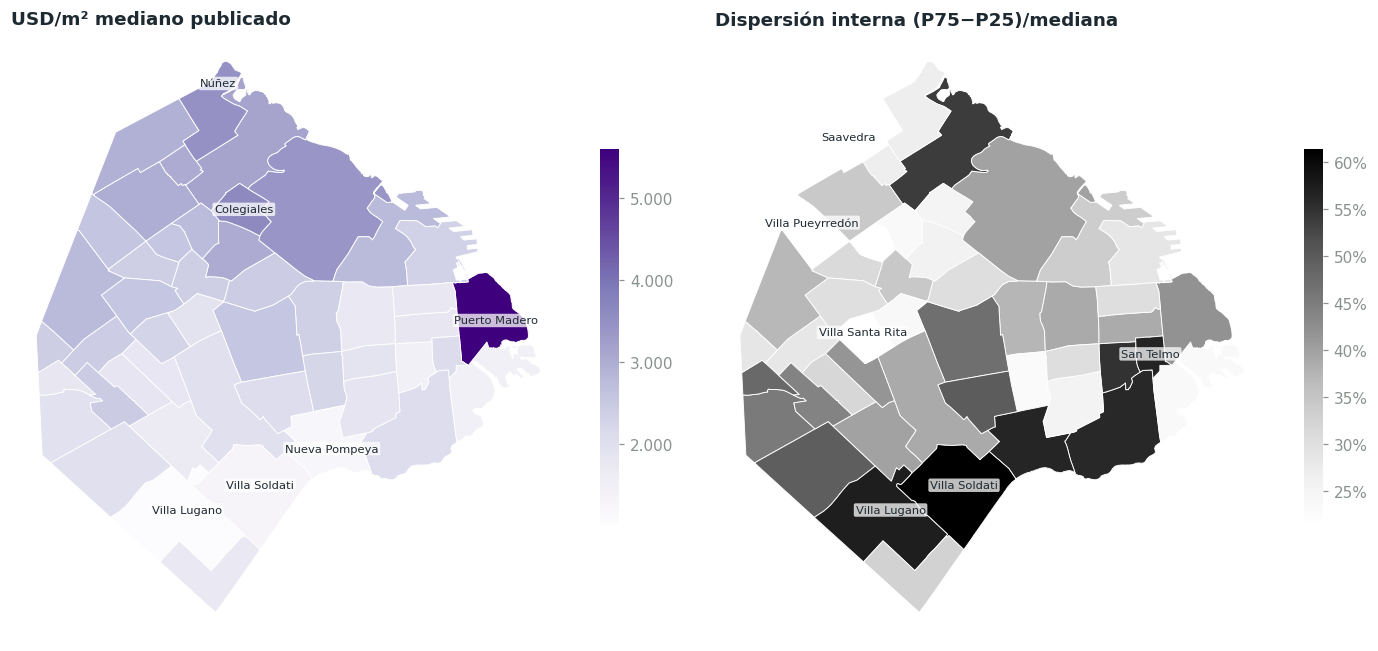

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 6))
mapa_barrios(barrios['usd_m2'], 'USD/m² mediano publicado', ax=axes[0])
mapa_barrios((barrios['p75'] - barrios['p25']) / barrios['usd_m2'], 'Dispersión interna (P75−P25)/mediana',
             fmt=lambda x: f'{x:.0%}', ax=axes[1], cmap='Greys')
plt.tight_layout(); plt.show()

**Lectura.** El gradiente norte–sur es fuerte: Puerto Madero (5.608 USD/m²), Colegiales, Núñez y Palermo arriba;
Villa Lugano (1.007), Nueva Pompeya y Villa Soldati abajo. Pero la **dispersión dentro de cada barrio** también es
grande: el rango P25–P75 va del 22 % al 60 % de la mediana, y es mayor en el sur (Villa Soldati, Villa Lugano) y en
barrios mixtos como San Telmo y Belgrano. La mediana del barrio sola no alcanza para decir si un aviso está caro o
barato.

## 3. Qué explica el USD/m² dentro de un mismo barrio

Para comparar un aviso con sus pares hay que saber qué características mueven el precio por m². Se usa el
**USD/m² relativo a la mediana del barrio**, así el gradiente geográfico no tapa lo demás.

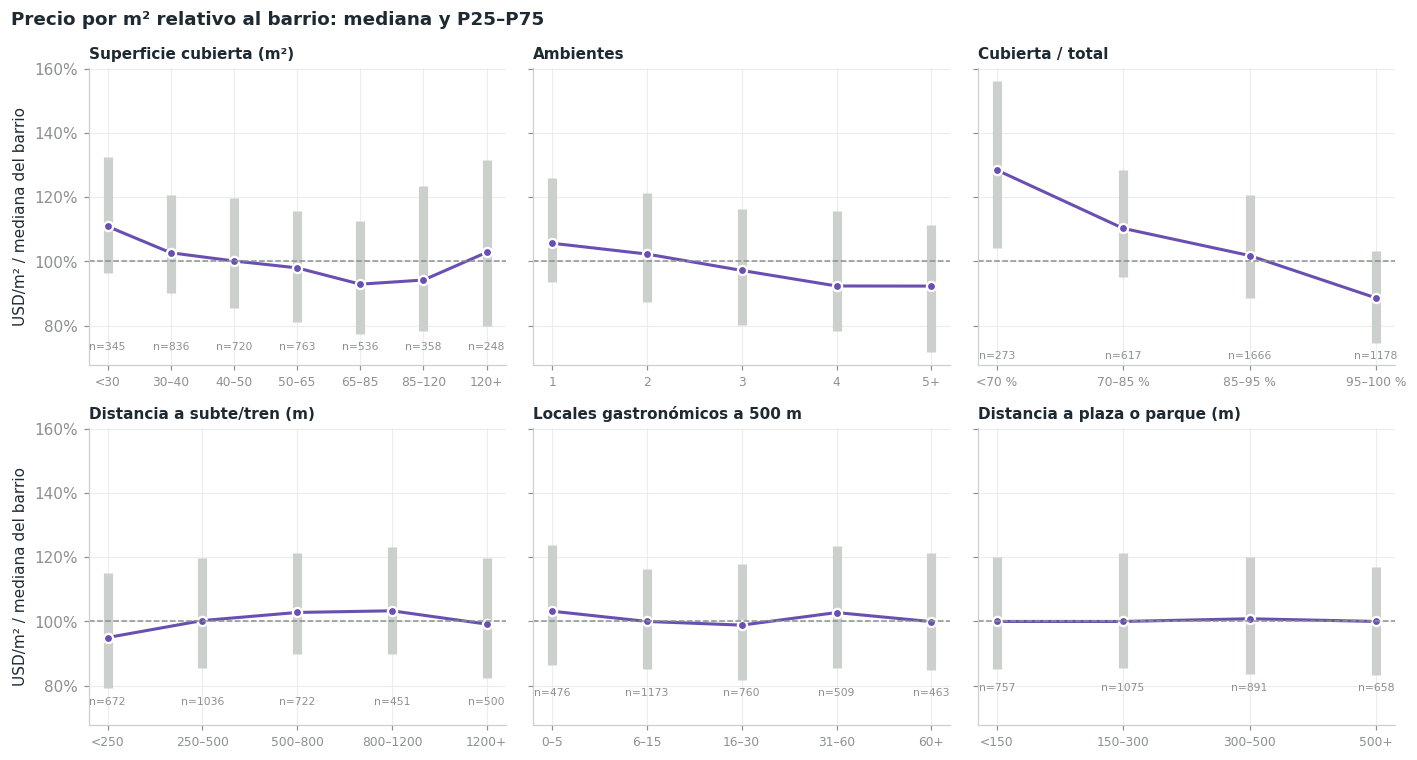

In [7]:
venta['rel_barrio'] = venta['precio_m2'] / venta.groupby('neighborhood')['precio_m2'].transform('median')

def perfil(col, bins, etiquetas=None, datos=venta):
    g = datos.groupby(pd.cut(datos[col], bins, labels=etiquetas), observed=True)['rel_barrio']
    return pd.DataFrame({'mediana': g.median(), 'p25': g.quantile(.25), 'p75': g.quantile(.75), 'n': g.size()})

paneles = [
    ('Superficie cubierta (m²)', perfil('covered_area', [0, 30, 40, 50, 65, 85, 120, 1000],
                                        ['<30', '30–40', '40–50', '50–65', '65–85', '85–120', '120+'])),
    ('Ambientes', perfil('rooms', [0, 1, 2, 3, 4, 20], ['1', '2', '3', '4', '5+'])),
    ('Cubierta / total', perfil('ratio_cubierta', [0, .7, .85, .95, 1.01], ['<70 %', '70–85 %', '85–95 %', '95–100 %'])),
    ('Distancia a subte/tren (m)', perfil('dist_transporte_m', [-1, 250, 500, 800, 1200, 5000],
                                          ['<250', '250–500', '500–800', '800–1200', '1200+'])),
    ('Locales gastronómicos a 500 m', perfil('gastronomia_500m', [-1, 5, 15, 30, 60, 500],
                                             ['0–5', '6–15', '16–30', '31–60', '60+'])),
    ('Distancia a plaza o parque (m)', perfil('dist_parque_m', [-1, 150, 300, 500, 5000], ['<150', '150–300', '300–500', '500+'])),
]
fig, axes = plt.subplots(2, 3, figsize=(13, 7), sharey=True)
for ax, (titulo, t) in zip(axes.flat, paneles):
    x = np.arange(len(t))
    ax.vlines(x, t['p25'], t['p75'], color=CORDON, lw=6)
    ax.plot(x, t['mediana'], color=JACARANDA, lw=2, marker='o', ms=6, mec='white', mew=1.5)
    ax.axhline(1, color=GRIS, lw=1, ls='--')
    ax.set_xticks(x, t.index.astype(str), fontsize=8)
    ax.set_title(titulo, fontsize=10)
    for xi, n in zip(x, t['n']):
        ax.annotate(f'n={n}', (xi, ax.get_ylim()[0] if False else t['p25'].min() - .05), ha='center', fontsize=7, color=GRIS)
axes[0, 0].set_ylabel('USD/m² / mediana del barrio'); axes[1, 0].set_ylabel('USD/m² / mediana del barrio')
axes[0, 0].yaxis.set_major_formatter(pct)
fig.suptitle('Precio por m² relativo al barrio: mediana y P25–P75', x=.01, ha='left', fontweight='semibold')
plt.tight_layout(); plt.show()

In [8]:
from scipy.stats import spearmanr

cols = {'covered_area': 'Superficie cubierta', 'rooms': 'Ambientes', 'ratio_cubierta': 'Cubierta / total',
        'm2_por_ambiente': 'm² por ambiente', 'dist_transporte_m': 'Distancia a transporte',
        'dist_parque_m': 'Distancia a parque', 'dist_hospital_m': 'Distancia a hospital',
        'gastronomia_500m': 'Gastronomía a 500 m', 'escuelas_500m': 'Escuelas a 500 m',
        'radio_delitos': 'Delitos registrados a 500 m (2025)'}
filas = []
for c, nombre in cols.items():
    d = venta[[c, 'rel_barrio']].dropna()
    rho, p = spearmanr(d[c], d['rel_barrio'])
    filas.append({'variable': nombre, 'rho_spearman': rho, 'p': p, 'n': len(d)})
corr = pd.DataFrame(filas).set_index('variable').sort_values('rho_spearman')
display(corr.style.format({'rho_spearman': '{:+.2f}', 'p': '{:.1e}', 'n': '{:,}'}).bar(subset='rho_spearman', align=0, color=[AZUL, NARANJA]))

,rho_spearman,p,n
variable,,,
Cubierta / total,-0.37,2.3e-123,"3,734"
Ambientes,-0.19,5.2e-32,"3,806"
Superficie cubierta,-0.15,7.7e-20,"3,806"
Escuelas a 500 m,-0.05,2.7e-03,"3,381"
Delitos registrados a 500 m (2025),-0.05,4.1e-03,"3,381"
Distancia a hospital,-0.03,1.1e-01,"3,381"
Distancia a parque,-0.01,4.1e-01,"3,381"
Gastronomía a 500 m,+0.01,5.9e-01,"3,381"
Distancia a transporte,+0.07,1.1e-04,"3,381"


In [9]:
# Expensas: costo mensual que la búsqueda hoy no muestra.
exp = venta.dropna(subset=['expenses']).copy()
exp['expensas_m2'] = exp['expenses'] / exp['covered_area']
print(f"Avisos con expensas informadas: {len(exp):,} ({len(exp)/len(venta):.0%}) · mediana ARS {miles(exp['expenses'].median())} por mes")
rho, _ = spearmanr(exp['expensas_m2'], exp['rel_barrio'])
print(f'Correlación expensas/m² con USD/m² relativo al barrio: rho = {rho:+.2f}')
eb = exp.groupby('neighborhood').agg(n=('id', 'size'), expensas_m2=('expensas_m2', 'median')).query('n >= 15')
display(eb.sort_values('expensas_m2', ascending=False).head(8).style.format({'expensas_m2': 'ARS {:,.0f}'}))

Avisos con expensas informadas: 1,606 (42%) · mediana ARS 180.000 por mes
Correlación expensas/m² con USD/m² relativo al barrio: rho = +0.27


,n,expensas_m2
neighborhood,,
Puerto Madero,37,"ARS 8,647"
Palermo,37,"ARS 5,294"
Núñez,19,"ARS 5,292"
San Telmo,32,"ARS 5,104"
Recoleta,45,"ARS 5,063"
Belgrano,30,"ARS 4,886"
Retiro,41,"ARS 4,839"
Chacarita,20,"ARS 4,639"


**Lectura.**
- **Dentro de un barrio, lo que más mueve el USD/m² es la estructura del departamento, no su ubicación fina.**
  La proporción cubierta/total es la variable más fuerte (rho −0,37): cuando menos del 70 % es cubierto
  (balcón, terraza, patio), el USD/m² *cubierto* queda cerca de 28 % arriba de la mediana del barrio, porque el
  precio también paga lo descubierto. Comparar solo por m² cubiertos castiga a esos avisos.
- **Tamaño:** los departamentos de menos de 30 m² piden ~11 % más por m²; el mínimo está entre 65 y 120 m², y los
  de más de 120 m² vuelven a la mediana (son de categoría). Con la misma superficie, **más ambientes = menos USD/m²**.
- **Ubicación fina:** una vez fijado el barrio, la distancia a transporte, a parques y la gastronomía cercana casi
  no cambian el USD/m² (|rho| ≤ 0,07). El efecto de la ubicación que encontró el modelo es sobre todo
  *entre* barrios y zonas, no dentro de cada uno. Los delitos registrados a 500 m tampoco se asocian (rho −0,05).
- **Expensas:** faltan en el 58 % de los avisos (RE/MAX, Century 21 y Migliorisi no las publican en la captura).
  Cuando están, las expensas por m² suben con el USD/m² relativo (rho +0,27): edificios con amenities.

> **Para la app · comparación y alertas.** (1) Comparar cada aviso contra avisos de **tamaño y ambientes
> parecidos**, no contra la mediana del barrio. (2) Mostrar el **costo mensual** (expensas) cuando exista y
> marcar "expensas no informadas" cuando no. (3) Mostrar la proporción descubierta ("incluye 12 m² de balcón")
> para que el USD/m² no engañe.

## 3 bis. Antigüedad y estado del edificio

Son los dos datos que más pueden explicar por qué un aviso pide menos que sus pares. Se unen por ID de aviso:
- **Zonaprop** publica la antigüedad (y las cocheras) en sus características. Se tomó de los mismos resultados
  de la captura del 8 de noviembre de 2026, sin una corrida nueva. No publica el estado.
- **Century 21** publica antigüedad y estado, y **Migliorisi** solo antigüedad. Se tomaron en una captura
  posterior (9 de noviembre), así que quedan sin dato los avisos que ya no estaban publicados.
- **RE/MAX** no publica ninguno de los dos en su búsqueda.

El **estado** solo está para Century 21: lo que se diga del estado vale para ese subconjunto.
En Zonaprop, el 27 % de los avisos declara antigüedad 0. Puede incluir avisos que dejaron el valor por defecto,
así que "a estrenar" es algo menos preciso en esa fuente.

In [10]:
TIENE_EDIFICIO = 'age_years' in venta.columns and venta['age_years'].notna().any()
if not TIENE_EDIFICIO:
    print('El paquete no trae datos del edificio: regeneralo con una captura *-edificio.')
else:
    cob = venta.groupby('agency').agg(avisos=('id', 'size'), con_antiguedad=('age_years', lambda s: s.notna().mean()),
                                      con_estado=('condition', lambda s: s.notna().mean()))
    display(cob.sort_values('avisos', ascending=False).style.format({'con_antiguedad': '{:.0%}', 'con_estado': '{:.0%}'}))
    print(f"Con antigüedad: {venta['age_years'].notna().sum():,} avisos · con estado: {venta['condition'].notna().sum():,}".replace(',', '.'))

,avisos,con_antiguedad,con_estado
agency,,,
zonaprop,2272,94%,0%
remax,583,0%,0%
century21,545,76%,86%
migliorisi,388,100%,0%
clarin,18,0%,0%


Con antigüedad: 2.937 avisos · con estado: 471


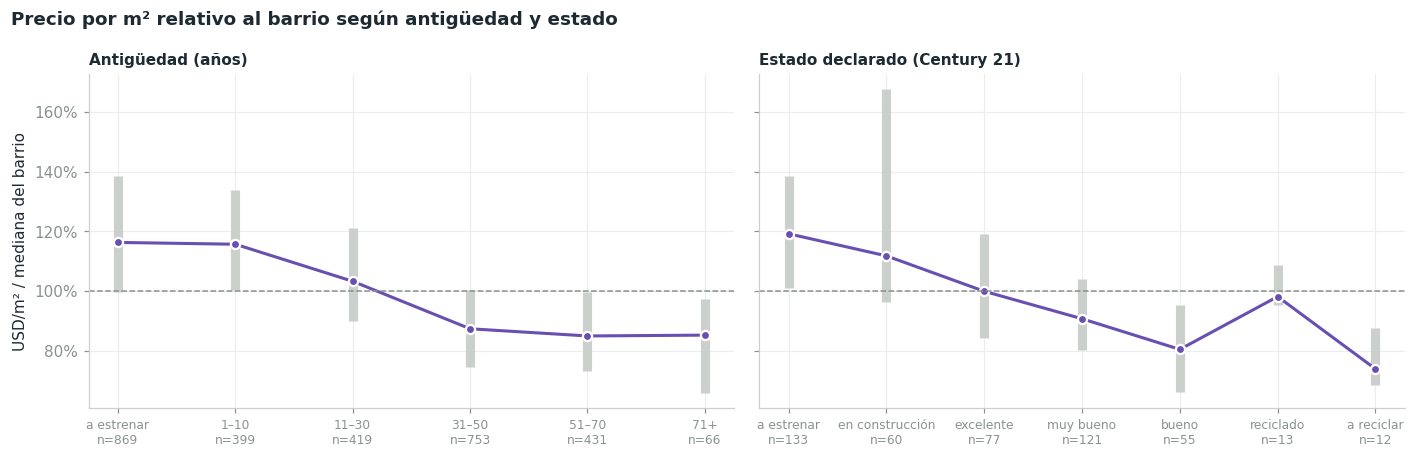

Antigüedad vs. USD/m² relativo al barrio: rho = -0.51 (p = 1.6e-198, n = 2937)


antiguedad,a estrenar,1–10,11–30,31–50,51–70,71+
agency,,,,,,
century21,120%,114%,112%,86%,86%,72%
migliorisi,128%,123%,93%,86%,80%,70%
zonaprop,112%,116%,104%,88%,85%,91%


In [11]:
if TIENE_EDIFICIO:
    ORDEN_ESTADO = ['a estrenar', 'en construcción', 'excelente', 'muy bueno', 'bueno', 'regular', 'reciclado', 'a reciclar']
    venta['antiguedad'] = pd.cut(venta['age_years'], [-1, 0, 10, 30, 50, 70, 300],
                                 labels=['a estrenar', '1–10', '11–30', '31–50', '51–70', '71+'])
    con_edad = venta.dropna(subset=['age_years'])
    t_edad = con_edad.groupby('antiguedad', observed=True)['rel_barrio'].agg(
        mediana='median', p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75), n='size')
    con_estado = venta.dropna(subset=['condition'])
    t_estado = con_estado.groupby('condition')['rel_barrio'].agg(
        mediana='median', p25=lambda s: s.quantile(.25), p75=lambda s: s.quantile(.75), n='size')
    t_estado = t_estado.reindex([e for e in ORDEN_ESTADO if e in t_estado.index])

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
    for ax, (titulo, t) in zip(axes, [('Antigüedad (años)', t_edad), ('Estado declarado (Century 21)', t_estado)]):
        x = np.arange(len(t))
        ax.vlines(x, t['p25'], t['p75'], color=CORDON, lw=6)
        ax.plot(x, t['mediana'], color=JACARANDA, lw=2, marker='o', ms=6, mec='white', mew=1.5)
        ax.axhline(1, color=GRIS, lw=1, ls='--')
        ax.set_xticks(x, [f'{i}\nn={n}' for i, n in zip(t.index.astype(str), t['n'])], fontsize=8)
        ax.set_title(titulo, fontsize=10)
    axes[0].set_ylabel('USD/m² / mediana del barrio'); axes[0].yaxis.set_major_formatter(pct)
    fig.suptitle('Precio por m² relativo al barrio según antigüedad y estado', x=.01, ha='left', fontweight='semibold')
    plt.tight_layout(); plt.show()

    rho, p = spearmanr(con_edad['age_years'], con_edad['rel_barrio'])
    print(f'Antigüedad vs. USD/m² relativo al barrio: rho = {rho:+.2f} (p = {p:.1e}, n = {len(con_edad)})')
    # ¿Cambia con la fuente? Cada fuente por separado.
    display(con_edad.groupby(['agency', 'antiguedad'], observed=True)['rel_barrio'].median().unstack().style.format('{:.0%}'))

**Lectura.**
- **La antigüedad es la variable que más mueve el USD/m² dentro de un barrio** de todo el EDA (rho −0,51 en los
  2.937 avisos con dato, contra −0,37 de la proporción cubierta). Hasta los 10 años, un departamento pide
  alrededor de 16 % más que la mediana de su barrio; de 11 a 30 años, casi la mediana; con más de 30 años, entre
  13 % y 15 % menos. Entre los dos grupos hay unos 30 puntos de diferencia, más que entre muchos barrios.
- **El salto está alrededor de los 30 años**, no es una pendiente pareja: pasados los 30, tener 40 o 70 años
  cambia poco.
- **El patrón se repite en las tres fuentes** (rho −0,48 en Zonaprop, −0,56 en Century 21 y −0,66 en
  Migliorisi), así que no es un efecto de una inmobiliaria. En Century 21 y Migliorisi la caída sigue después de
  los 70 años; en Zonaprop, no.
- **El estado ordena el precio en el mismo sentido:** de a estrenar (+19 %) a bueno (−19 %) y a reciclar (−26 %).
  *Reciclado* vuelve cerca de la mediana: el reciclado recupera buena parte del valor. Hay pocos casos de
  reciclado y a reciclar (13 y 12), así que esos dos puntos son orientativos.
- Antigüedad y estado están muy relacionados (lo nuevo suele declararse a estrenar o excelente), pero el estado
  agrega información en los edificios viejos: un 50 años "muy bueno" no pide lo mismo que uno "a reciclar".

> **Para la app · preferencias y comparación.** (1) Un filtro de antigüedad (*a estrenar / hasta 10 años / hasta
> 30 / cualquiera*) y de estado cuando la fuente lo publique, marcando "sin dato" en vez de excluir. (2) Comparar
> cada aviso contra avisos **de antigüedad parecida**: "pide 10 % menos que departamentos de 40 a 60 años del
> barrio" es más justo que compararlo con todo el barrio. (3) Mostrar qué fuentes no publican antigüedad para
> que la persona sepa que falta el dato.

## 4. ¿Dónde rinde el presupuesto? Umbrales de entrada por barrio

La app hoy filtra por presupuesto, m² mínimos y ambientes. La pregunta exploratoria: **¿cuánto cambia la oferta
si la persona mueve un poco el presupuesto?** Se toma como ejemplo la búsqueda típica de la app: 2 ambientes o
más y 40 m² cubiertos o más.

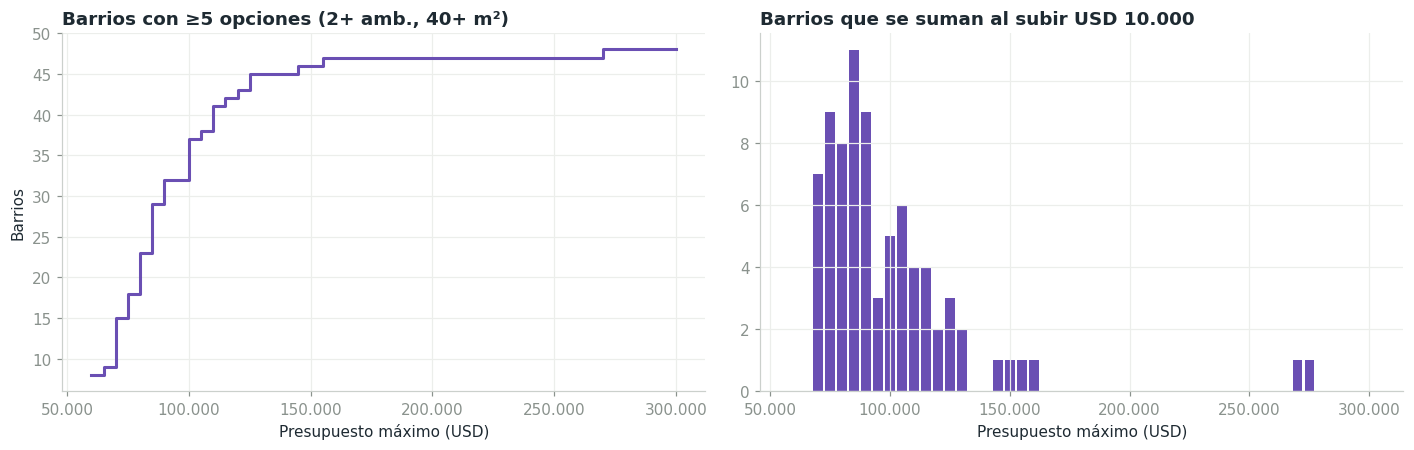

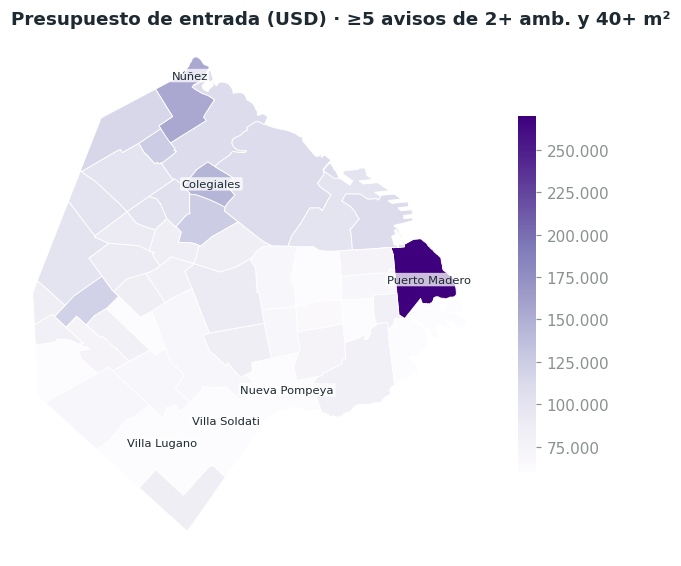

In [12]:
MIN_AMB, MIN_M2, MIN_OPCIONES = 2, 40, 5
apto = venta[(venta['rooms'] >= MIN_AMB) & (venta['covered_area'] >= MIN_M2)]
presupuestos = np.arange(60_000, 300_001, 5_000)

oferta = pd.DataFrame({p: apto[apto['price'] <= p].groupby('neighborhood').size() for p in presupuestos}).fillna(0).astype(int)
oferta = oferta.reindex(barrios.index).fillna(0).astype(int)
barrios_abiertos = (oferta >= MIN_OPCIONES).sum()
total_avisos = oferta.sum()

# Presupuesto de entrada: el mínimo con el que el barrio tiene al menos MIN_OPCIONES avisos que encajan.
entrada = oferta.ge(MIN_OPCIONES).idxmax(axis=1).where(oferta.ge(MIN_OPCIONES).any(axis=1))
barrios['presupuesto_entrada'] = entrada

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
axes[0].step(presupuestos, barrios_abiertos, where='post', color=JACARANDA, lw=2)
axes[0].set_title(f'Barrios con ≥{MIN_OPCIONES} opciones ({MIN_AMB}+ amb., {MIN_M2}+ m²)')
axes[0].set_ylabel('Barrios'); axes[0].xaxis.set_major_formatter(usd); axes[0].set_xlabel('Presupuesto máximo (USD)')
ganancia = barrios_abiertos.diff(2).fillna(0)  # barrios que se suman con +USD 10.000
axes[1].bar(presupuestos, ganancia, width=4000, color=JACARANDA)
axes[1].set_title('Barrios que se suman al subir USD 10.000'); axes[1].xaxis.set_major_formatter(usd)
axes[1].set_xlabel('Presupuesto máximo (USD)')
plt.tight_layout(); plt.show()

mapa_barrios(barrios['presupuesto_entrada'], f'Presupuesto de entrada (USD) · ≥{MIN_OPCIONES} avisos de {MIN_AMB}+ amb. y {MIN_M2}+ m²',
             cmap='Purples')
plt.show()

In [13]:
def empujon(presupuesto, extra=10_000):
    # Qué gana la persona si estira el presupuesto: barrios nuevos y avisos nuevos.
    p0 = presupuestos[presupuestos <= presupuesto].max()
    p1 = presupuestos[presupuestos <= presupuesto + extra].max()
    nuevos = oferta.index[(oferta[p0] < MIN_OPCIONES) & (oferta[p1] >= MIN_OPCIONES)].tolist()
    return {'presupuesto': presupuesto, 'extra': extra, 'avisos_antes': int(total_avisos[p0]),
            'avisos_despues': int(total_avisos[p1]), 'barrios_nuevos': nuevos}

tabla_empujon = pd.DataFrame([empujon(p) for p in (80_000, 100_000, 110_000, 130_000, 150_000, 200_000)])
tabla_empujon['avisos_extra_%'] = tabla_empujon['avisos_despues'] / tabla_empujon['avisos_antes'] - 1
display(tabla_empujon.style.format({'avisos_extra_%': '{:+.0%}'}))

,presupuesto,extra,avisos_antes,avisos_despues,barrios_nuevos,avisos_extra_%
0,80000,10000,340,514,"['Villa Riachuelo', 'Parque Chacabuco', 'Villa Santa Rita', 'La Paternal', 'Agronomía', 'Villa Real', 'Villa Crespo', 'Villa del Parque', 'Caballito']",+51%
1,100000,10000,665,786,"['Retiro', 'Villa Ortúzar', 'Belgrano', 'Palermo']",+18%
2,110000,10000,786,947,"['Monte Castro', 'Saavedra']",+20%
3,130000,10000,1143,1269,[],+11%
4,150000,10000,1393,1502,['Núñez'],+8%
5,200000,10000,1883,1921,[],+2%


**Lectura.** La oferta no crece de forma pareja con el presupuesto: hay **escalones**. Para la búsqueda tipo,
pasar de USD 80.000 a 90.000 suma 9 barrios y un 51 % más de avisos; de 100.000 a 110.000 se suman Belgrano,
Palermo, Retiro y Villa Ortúzar. Desde USD 150.000 casi todos los barrios ya tienen opciones y USD 10.000 más agregan
menos del 10 % de avisos. El presupuesto de entrada dibuja
un mapa muy distinto al de la mediana de USD/m², porque depende también de cuántos departamentos chicos hay.

> **Para la app · preferencias.** Debajo del campo de presupuesto, un aviso del tipo *"Con USD 10.000 más se
> suman Belgrano, Palermo, Retiro y Villa Ortúzar (121 avisos más)"*, o al revés, *"Con USD 5.000 menos seguís teniendo los mismos barrios"*.
> Es información accionable, sin puntajes, y se calcula con la misma consulta que ya hace la comparación.

## 5. Entorno y precio a nivel barrio

Se cruza la mediana de USD/m² con el perfil de entorno de cada barrio (capas de BA Data que ya muestra el mapa)
y con los delitos registrados en 2025. Son 48 barrios: las correlaciones son descriptivas, no causales.

In [14]:
def perfil_entorno(nombre, e):
    esc = sum(sum(v.values()) for v in e['escuelas'].values())
    return {'barrio': nombre, 'comuna': e['comuna'], 'area_ha': e['area_ha'],
            'subte_estaciones': e['subte_estaciones'], 'subte_x_100ha': e['subte_estaciones'] / e['area_ha'] * 100,
            'verde_pct': e['verdes_ha'] / e['area_ha'], 'escuelas_x_100ha': esc / e['area_ha'] * 100,
            'salud': e['cesac'] + e['hospitales'], 'ruido_alto_noche': e['ruido']['nocturno']['alto'],
            'riesgo_hidrico': e['riesgo_hidrico']}

ent = pd.DataFrame([perfil_entorno(k, v) for k, v in entorno.items()]).set_index('barrio')
d25 = delitos_anio[delitos_anio['anio'] == 2025].set_index('barrio')
ent['delitos_2025_x_ha'] = d25['total_delitos'] / ent['area_ha']
ent['pct_con_arma_2025'] = d25['pct_con_arma']
loc = venta.groupby('neighborhood')[['dist_transporte_m', 'gastronomia_500m']].median()
ent = ent.join(loc.rename(columns={'dist_transporte_m': 'dist_transporte_mediana', 'gastronomia_500m': 'gastronomia_mediana'}))
bx = barrios.join(ent)

nombres = {'subte_x_100ha': 'Estaciones de subte /100 ha', 'verde_pct': 'Superficie verde (%)',
           'escuelas_x_100ha': 'Escuelas /100 ha', 'ruido_alto_noche': 'Ruido nocturno alto (% celdas)',
           'riesgo_hidrico': 'Riesgo hídrico (% área)', 'dist_transporte_mediana': 'Distancia mediana a transporte',
           'gastronomia_mediana': 'Gastronomía mediana a 500 m', 'delitos_2025_x_ha': 'Delitos registrados 2025 / ha',
           'pct_con_arma_2025': '% delitos con arma 2025'}
filas = []
for c, n in nombres.items():
    d = bx[[c, 'usd_m2']].dropna()
    rho, p = spearmanr(d[c], d['usd_m2'])
    filas.append({'variable': n, 'rho': rho, 'p': p})
corr_b = pd.DataFrame(filas).set_index('variable').sort_values('rho')
display(corr_b.style.format({'rho': '{:+.2f}', 'p': '{:.3f}'}).bar(subset='rho', align=0, color=[AZUL, NARANJA]))

,rho,p
variable,,
% delitos con arma 2025,-0.50,0.000
Ruido nocturno alto (% celdas),-0.31,0.032
Delitos registrados 2025 / ha,-0.24,0.105
Distancia mediana a transporte,-0.07,0.628
Estaciones de subte /100 ha,-0.00,0.973
Riesgo hídrico (% área),+0.05,0.757
Escuelas /100 ha,+0.09,0.560
Superficie verde (%),+0.12,0.418
Gastronomía mediana a 500 m,+0.42,0.003


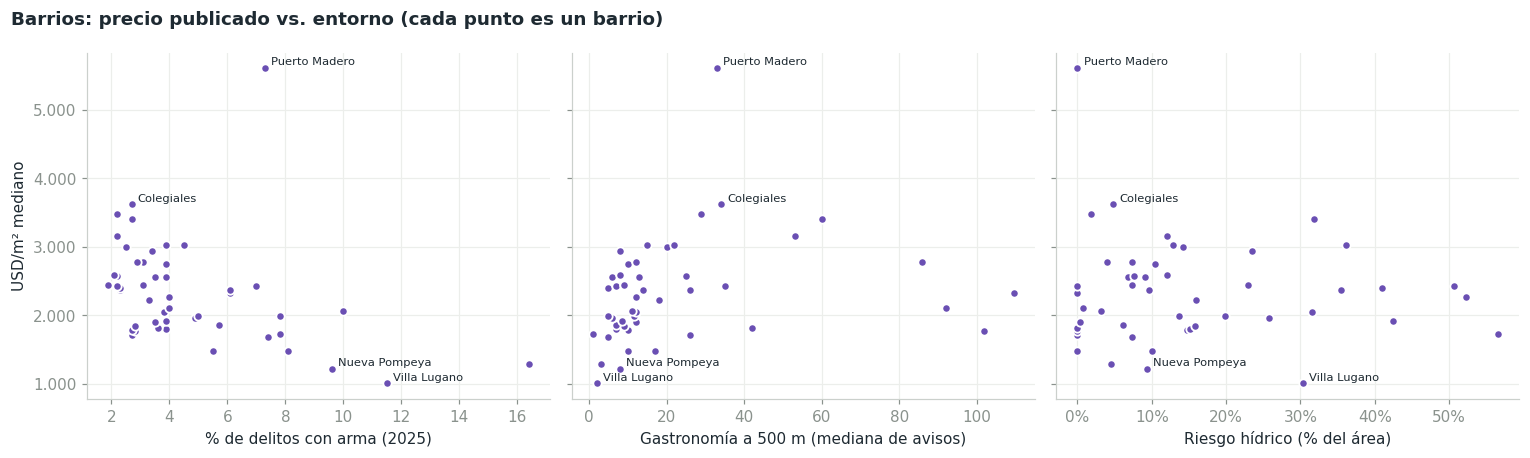

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (c, etiqueta, fmt) in zip(axes, [('pct_con_arma_2025', '% de delitos con arma (2025)', None),
                                         ('gastronomia_mediana', 'Gastronomía a 500 m (mediana de avisos)', None),
                                         ('riesgo_hidrico', 'Riesgo hídrico (% del área)', pct)]):
    ax.scatter(bx[c], bx['usd_m2'], s=30, color=JACARANDA, edgecolor='white', linewidth=1.2, zorder=3)
    for b in bx['usd_m2'].nlargest(2).index.tolist() + bx['usd_m2'].nsmallest(2).index.tolist():
        ax.annotate(b, (bx.loc[b, c], bx.loc[b, 'usd_m2']), xytext=(4, 2), textcoords='offset points', fontsize=7.5)
    ax.set_xlabel(etiqueta)
    if fmt is not None:
        ax.xaxis.set_major_formatter(fmt)
axes[0].set_ylabel('USD/m² mediano'); axes[0].yaxis.set_major_formatter(usd)
fig.suptitle('Barrios: precio publicado vs. entorno (cada punto es un barrio)', x=.01, ha='left', fontweight='semibold')
plt.tight_layout(); plt.show()

**Lectura.**
- Entre barrios, el USD/m² se asocia con **la gastronomía cercana a los avisos** (rho +0,42), con **menos ruido
  nocturno alto** (−0,31) y, sobre todo, con **el porcentaje de delitos con arma** (−0,50): ese porcentaje es más
  alto en el sur, donde los precios son más bajos.
- **La cantidad total de delitos por hectárea no se asocia de forma significativa** (rho −0,24, p = 0,11): es
  alta tanto en barrios caros con mucho movimiento (Palermo, Recoleta) como en barrios baratos del centro y el sur.
- La densidad de subte, el verde y el riesgo hídrico no se asocian con el precio a esta escala.
- Esto coincide con el modelo del capstone: los delitos no mejoran la predicción una vez que se controla por
  ubicación y servicios. La composición (con arma) describe el entorno, pero acompaña al gradiente norte–sur.

> **Para la app · mapa y comparación.** Mantener los delitos como capa de contexto con su período y unidad, y
> mostrar **tipo y franja horaria** además del total (la cantidad sola confunde movimiento con riesgo). No
> usarlos para ordenar barrios.

## 5 bis. Correlaciones lineales y no lineales

Hasta acá se usó Spearman, que mide si dos variables suben o bajan juntas aunque no lo hagan en línea recta.
Esta sección lo compara con **Pearson**, que mide solo la parte **lineal** y es sensible a valores extremos, y
dibuja cada relación con dos líneas:

- **Recta de ajuste** (mínimos cuadrados): lo que resume Pearson.
- **Curva suavizada** (LOWESS, regresión local ponderada): sigue la forma de los datos sin suponer una recta.
  Muestra relaciones **no monótonas**, como una U, que ni Pearson ni Spearman captan bien.

Cómo leer la tabla:
- **Spearman bastante más fuerte que Pearson:** la relación es monótona pero curva, o hay extremos que la tapan.
- **Pearson más fuerte que Spearman:** unos pocos valores extremos arrastran la recta.
- **Ambos cerca de 0 pero la curva se dobla:** hay una relación no monótona; mirar el gráfico.

Se analizan dos niveles por separado, porque responden preguntas distintas:
1. **Por aviso** (hasta 3.806 avisos de venta): qué características se asocian con pedir más o menos que la
   mediana del barrio. La variable de respuesta es el **USD/m² relativo a la mediana del barrio** (1 = mediana).
2. **Por barrio** (48 barrios): qué rasgos del entorno acompañan al nivel de precio. La respuesta es el
   **USD/m² mediano del barrio**. Con 48 puntos, cada barrio pesa mucho y los p-valores son orientativos.

Cada variable informa su unidad, cuántos datos tiene (n) y qué parte falta. Las correlaciones describen
asociaciones en precios de publicación; no son causales.

In [16]:
from scipy.stats import pearsonr

def lowess(x, y, frac=.3, puntos=60):
    # Regresión local ponderada con pesos tricúbicos, sin statsmodels. Devuelve la curva sobre una grilla de x.
    x, y = np.asarray(x, float), np.asarray(y, float)
    grilla = np.unique(np.quantile(x, np.linspace(.02, .98, puntos)))
    k = min(max(int(frac * len(x)), 10), len(x))
    curva = []
    for g in grilla:
        dist = np.abs(x - g)
        h = np.partition(dist, k - 1)[k - 1] or 1e-9
        w = np.clip(1 - (dist / h) ** 3, 0, None) ** 3
        xm, ym = np.average(x, weights=w), np.average(y, weights=w)
        var = np.sum(w * (x - xm) ** 2)
        pendiente = np.sum(w * (x - xm) * (y - ym)) / var if var > 0 else 0
        curva.append(ym + pendiente * (g - xm))
    return grilla, np.array(curva)


def tabla_correlaciones(datos, respuesta, variables):
    # variables: {columna: (nombre, unidad)}. Pearson también sin el 1 % de extremos de cada lado de la respuesta.
    filas = []
    lo, hi = datos[respuesta].quantile([.01, .99])
    for c, (nombre, unidad) in variables.items():
        d = datos[[c, respuesta]].dropna()
        r, p_r = pearsonr(d[c], d[respuesta])
        rho, p_rho = spearmanr(d[c], d[respuesta])
        sin_ext = d[d[respuesta].between(lo, hi)]
        filas.append({'variable': nombre, 'unidad': unidad, 'n': len(d), 'faltante': 1 - len(d) / len(datos),
                      'pearson': r, 'p_pearson': p_r, 'pearson_sin_extremos': pearsonr(sin_ext[c], sin_ext[respuesta])[0],
                      'spearman': rho, 'p_spearman': p_rho, 'spearman_menos_pearson': rho - r})
    return pd.DataFrame(filas).set_index('variable').sort_values('spearman')


def mostrar_tabla(t):
    return (t.style.format({'n': '{:,}', 'faltante': '{:.0%}', 'pearson': '{:+.2f}', 'p_pearson': '{:.1e}',
                            'pearson_sin_extremos': '{:+.2f}', 'spearman': '{:+.2f}', 'p_spearman': '{:.1e}',
                            'spearman_menos_pearson': '{:+.2f}'})
            .bar(subset=['pearson', 'spearman'], align=0, color=[AZUL, NARANJA]))


def dispersion(ax, datos, x, y, titulo, unidad, frac=.3, log_x=False, ylim=None, etiquetar=None):
    d = datos[[x, y]].dropna()
    muchos = len(d) > 200
    ax.scatter(d[x], d[y], s=6 if muchos else 30, alpha=.18 if muchos else .9, color=GRIS if muchos else JACARANDA,
               edgecolor='none' if muchos else 'white', linewidth=0 if muchos else 1.2, zorder=2)
    pendiente, ordenada = np.polyfit(d[x], d[y], 1)
    xs = np.linspace(d[x].min(), d[x].max(), 100)
    ax.plot(xs, ordenada + pendiente * xs, color=NARANJA, lw=1.8, ls='--', label='Recta (Pearson)', zorder=3)
    gx, gy = lowess(d[x], d[y], frac=frac)
    ax.plot(gx, gy, color=JACARANDA if muchos else ASFALTO, lw=2.4, label='Curva suavizada (LOWESS)', zorder=4)
    r, rho = pearsonr(d[x], d[y])[0], spearmanr(d[x], d[y])[0]
    ax.set_title(f'{titulo}\nr = {r:+.2f} · rho = {rho:+.2f} · n = {len(d):,}'.replace(',', '.'), fontsize=9.5)
    ax.set_xlabel(unidad, fontsize=8.5)
    if log_x:
        ax.set_xscale('log')
    if ylim:
        ax.set_ylim(*ylim)
    for b in etiquetar or []:
        if b in d.index:
            ax.annotate(b, (d.loc[b, x], d.loc[b, y]), xytext=(4, 2), textcoords='offset points', fontsize=7)

### Por aviso: USD/m² relativo a la mediana del barrio

In [17]:
venta['expensas_m2'] = venta['expenses'] / venta['covered_area']
VARS_AVISO = {
    'covered_area': ('Superficie cubierta', 'm²'), 'rooms': ('Ambientes', 'cantidad'),
    'm2_por_ambiente': ('m² por ambiente', 'm²'), 'ratio_cubierta': ('Cubierta / total', 'proporción 0–1'),
    'age_years': ('Antigüedad', 'años'), 'garages': ('Cocheras', 'cantidad'), 'floor': ('Piso', 'número de piso'),
    'expensas_m2': ('Expensas por m²', 'ARS por m² por mes'),
    'dist_transporte_m': ('Distancia a subte/tren', 'metros'), 'dist_parque_m': ('Distancia a plaza o parque', 'metros'),
    'gastronomia_500m': ('Gastronomía a 500 m', 'locales'), 'escuelas_500m': ('Escuelas a 500 m', 'establecimientos'),
    'radio_delitos': ('Delitos registrados a 500 m (2025)', 'hechos'),
}
VARS_AVISO = {c: v for c, v in VARS_AVISO.items() if c in venta.columns}
corr_aviso = tabla_correlaciones(venta, 'rel_barrio', VARS_AVISO)
display(mostrar_tabla(corr_aviso))
corr_aviso.to_csv(SALIDA / 'correlaciones_por_aviso.csv')

,unidad,n,faltante,pearson,p_pearson,pearson_sin_extremos,spearman,p_spearman,spearman_menos_pearson
variable,,,,,,,,,
Antigüedad,años,"2,937",23%,-0.45,4.4e-148,-0.49,-0.51,1.6e-198,-0.06
Cubierta / total,proporción 0–1,"3,734",2%,-0.35,5.2e-111,-0.36,-0.37,2.3e-123,-0.02
Ambientes,cantidad,"3,806",0%,-0.12,5.2e-13,-0.16,-0.19,5.2e-32,-0.07
Superficie cubierta,m²,"3,806",0%,+0.01,5.1e-01,-0.04,-0.15,7.7e-20,-0.16
Escuelas a 500 m,establecimientos,"3,381",11%,-0.04,9.1e-03,-0.07,-0.05,2.7e-03,-0.01
Delitos registrados a 500 m (2025),hechos,"3,381",11%,-0.03,4.9e-02,-0.04,-0.05,4.1e-03,-0.02
Distancia a plaza o parque,metros,"3,381",11%,-0.04,1.8e-02,-0.02,-0.01,4.1e-01,+0.03
Gastronomía a 500 m,locales,"3,381",11%,+0.05,3.6e-03,+0.02,+0.01,5.9e-01,-0.04
Piso,número de piso,259,93%,+0.02,6.9e-01,+0.06,+0.06,3.1e-01,+0.04


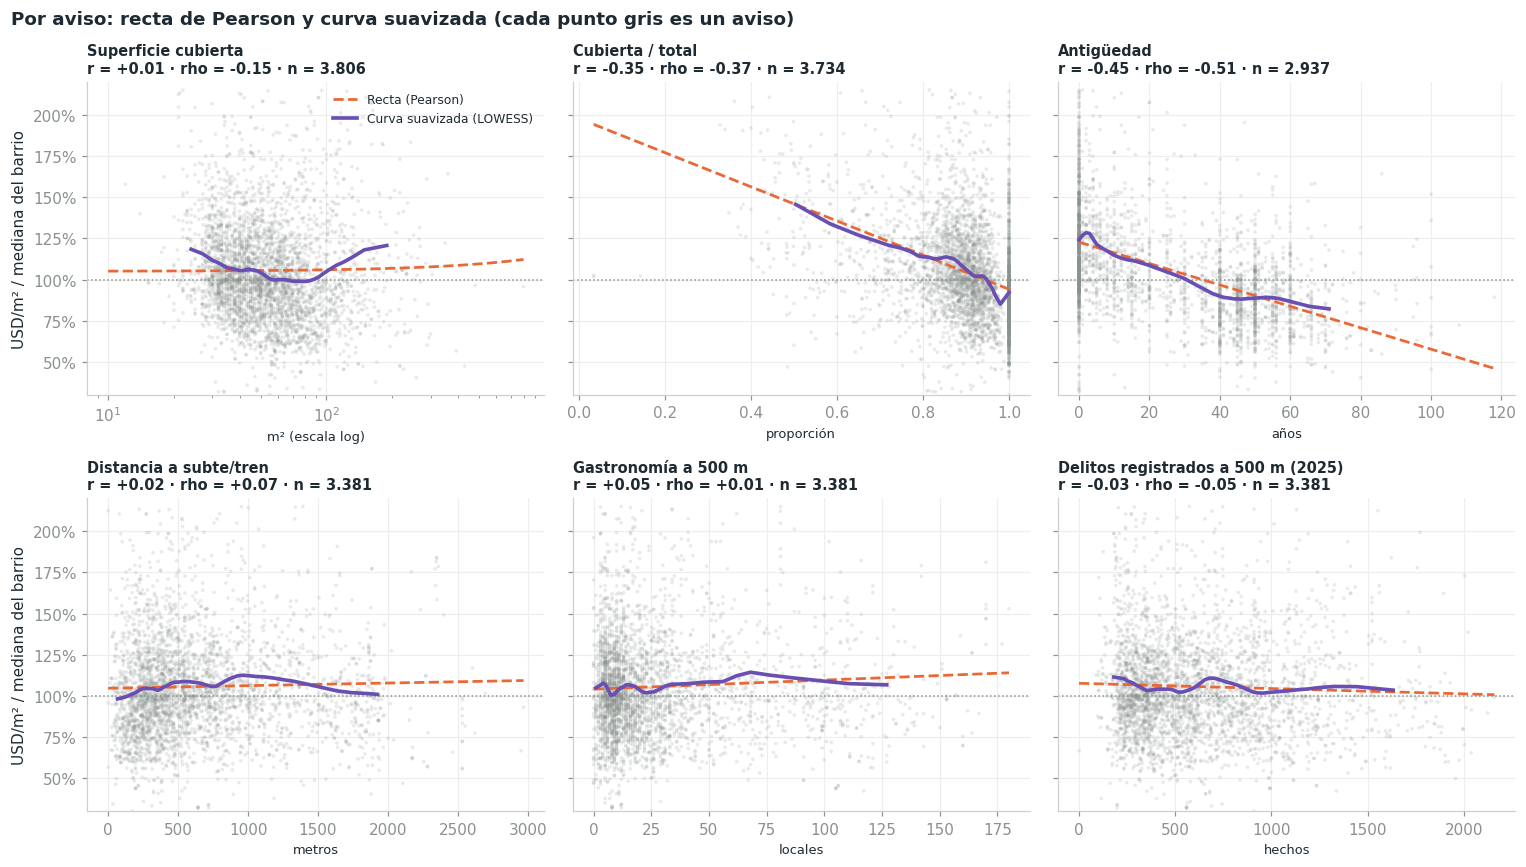

In [18]:
paneles = [('covered_area', 'Superficie cubierta', 'm² (escala log)', True),
           ('ratio_cubierta', 'Cubierta / total', 'proporción', False),
           ('age_years', 'Antigüedad', 'años', False),
           ('dist_transporte_m', 'Distancia a subte/tren', 'metros', False),
           ('gastronomia_500m', 'Gastronomía a 500 m', 'locales', False),
           ('radio_delitos', 'Delitos registrados a 500 m (2025)', 'hechos', False)]
fig, axes = plt.subplots(2, 3, figsize=(14, 8), sharey=True)
for ax, (c, titulo, unidad, log_x) in zip(axes.flat, paneles):
    dispersion(ax, venta, c, 'rel_barrio', titulo, unidad, frac=.25, log_x=log_x, ylim=(.3, 2.2))
    ax.axhline(1, color=GRIS, lw=1, ls=':')
for ax in axes[:, 0]:
    ax.set_ylabel('USD/m² / mediana del barrio'); ax.yaxis.set_major_formatter(pct)
axes[0, 0].legend(loc='upper right', fontsize=8)
fig.suptitle('Por aviso: recta de Pearson y curva suavizada (cada punto gris es un aviso)', x=.01, ha='left',
             fontweight='semibold')
plt.tight_layout(); plt.savefig(SALIDA / 'dispersion_por_aviso.png', dpi=150); plt.show()

### Por barrio: USD/m² mediano del barrio

In [19]:
VARS_BARRIO = {
    'gastronomia_mediana': ('Gastronomía a 500 m (mediana de sus avisos)', 'locales'),
    'dist_transporte_mediana': ('Distancia a subte/tren (mediana de sus avisos)', 'metros'),
    'subte_x_100ha': ('Estaciones de subte', 'por 100 ha'), 'verde_pct': ('Superficie verde', 'proporción del área'),
    'escuelas_x_100ha': ('Escuelas', 'por 100 ha'), 'ruido_alto_noche': ('Ruido nocturno alto', 'proporción de celdas'),
    'riesgo_hidrico': ('Riesgo hídrico', 'proporción del área'),
    'delitos_2025_x_ha': ('Delitos registrados 2025', 'hechos por ha'),
    'pct_con_arma_2025': ('Delitos con arma 2025', '% de los hechos'),
}
corr_barrio = tabla_correlaciones(bx, 'usd_m2', VARS_BARRIO)
display(mostrar_tabla(corr_barrio))
corr_barrio.to_csv(SALIDA / 'correlaciones_por_barrio.csv')

,unidad,n,faltante,pearson,p_pearson,pearson_sin_extremos,spearman,p_spearman,spearman_menos_pearson
variable,,,,,,,,,
Delitos con arma 2025,% de los hechos,48,0%,-0.37,9.1e-03,-0.55,-0.50,3.2e-04,-0.12
Ruido nocturno alto,proporción de celdas,48,0%,-0.28,5.2e-02,-0.27,-0.31,3.2e-02,-0.03
Delitos registrados 2025,hechos por ha,48,0%,-0.29,4.4e-02,-0.27,-0.24,1.1e-01,+0.05
Distancia a subte/tren (mediana de sus avisos),metros,48,0%,-0.11,4.7e-01,-0.18,-0.07,6.3e-01,+0.04
Estaciones de subte,por 100 ha,48,0%,-0.20,1.7e-01,-0.23,-0.00,9.7e-01,+0.20
Riesgo hídrico,proporción del área,48,0%,-0.08,5.9e-01,+0.07,+0.05,7.6e-01,+0.13
Escuelas,por 100 ha,48,0%,-0.10,4.9e-01,+0.14,+0.09,5.6e-01,+0.19
Superficie verde,proporción del área,48,0%,+0.05,7.4e-01,+0.07,+0.12,4.2e-01,+0.07
Gastronomía a 500 m (mediana de sus avisos),locales,48,0%,+0.22,1.4e-01,+0.21,+0.42,2.7e-03,+0.21


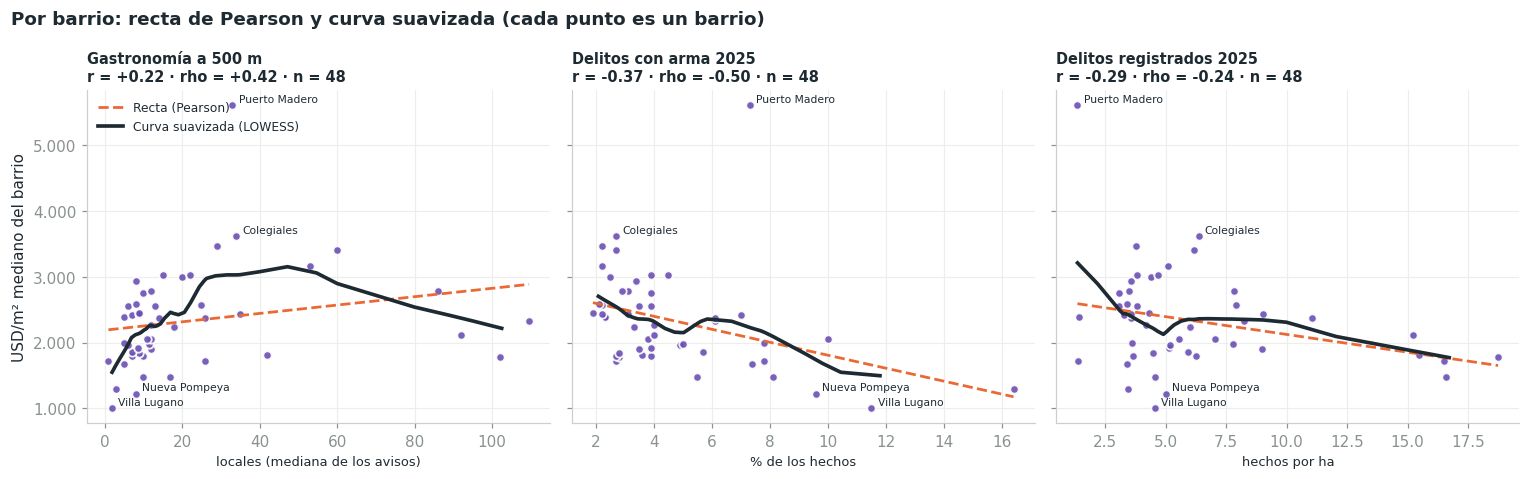

In [20]:
extremos = bx['usd_m2'].nlargest(2).index.tolist() + bx['usd_m2'].nsmallest(2).index.tolist()
paneles = [('gastronomia_mediana', 'Gastronomía a 500 m', 'locales (mediana de los avisos)'),
           ('pct_con_arma_2025', 'Delitos con arma 2025', '% de los hechos'),
           ('delitos_2025_x_ha', 'Delitos registrados 2025', 'hechos por ha')]
fig, axes = plt.subplots(1, 3, figsize=(14, 4.4), sharey=True)
for ax, (c, titulo, unidad) in zip(axes, paneles):
    dispersion(ax, bx, c, 'usd_m2', titulo, unidad, frac=.6, etiquetar=extremos)
axes[0].set_ylabel('USD/m² mediano del barrio'); axes[0].yaxis.set_major_formatter(usd)
axes[0].legend(loc='upper left', fontsize=8)
fig.suptitle('Por barrio: recta de Pearson y curva suavizada (cada punto es un barrio)', x=.01, ha='left',
             fontweight='semibold')
plt.tight_layout(); plt.savefig(SALIDA / 'dispersion_por_barrio.png', dpi=150); plt.show()

**Lectura.** En la columna *Pearson sin extremos* se saca el 1 % más alto y el 1 % más bajo de la respuesta. Por
barrio, eso deja afuera al más caro (Puerto Madero) y al más barato (Villa Lugano).

**Por aviso**
- **En las asociaciones fuertes, Pearson y Spearman coinciden.**
  - **Antigüedad** (r −0,45; rho −0,52; n = 2.937, falta el 23 %) y **proporción cubierta/total** (−0,35 y −0,37)
    son las más fuertes.
  - **Cocheras** (+0,25 y +0,22; falta el 34 %) y **expensas por m²** (+0,30 y +0,27; n = 1.606, falta el 58 %)
    suben con el precio relativo. Son señales de edificios de más categoría.
- **La superficie es el caso no lineal.** Pearson da casi 0 (r = +0,01) y Spearman, −0,15, pero la curva dibuja
  una **U**.
  - Los departamentos de menos de 30 m² piden más de 10 % por encima de la mediana de su barrio.
  - El mínimo está entre unos 60 y 100 m², y por encima de 120 m² la curva vuelve a subir.
  - Un solo coeficiente diría "casi no hay relación". En realidad la relación existe y cambia de sentido. Por eso
    conviene comparar contra avisos de tamaño parecido (sección 3).
- **La antigüedad tampoco es una recta.** La curva baja hasta los 40 años y después se aplana cerca de −12 %. La
  recta de Pearson, en cambio, sigue bajando y llega a casi −50 % pasados los 110 años, algo que los datos no
  muestran. En un modelo conviene usar tramos, como en la sección 3 bis, y no un término lineal.
- **Ubicación fina: no hay nada escondido.**
  - La distancia a subte o tren, la gastronomía y los delitos a 500 m dan |r| y |rho| ≤ 0,07.
  - La curva queda casi plana, así que los coeficientes no están tapando una relación no lineal.
  - Confirma lo que mostró la sección 3.

**Por barrio**

Con 48 barrios, uno o dos casos alcanzan para mover el coeficiente.
- **Gastronomía: Spearman +0,42 contra Pearson +0,22.**
  - La curva sube hasta unos 50 locales y después baja.
  - Los barrios con más gastronomía son Recoleta, San Telmo, San Nicolás y Retiro. Tienen precios intermedios:
    San Nicolás, con 102 locales, está en 1.776 USD/m².
  - Es una U invertida: Pearson la subestima.
- **Delitos con arma: Pearson −0,37, que llega a −0,55 sin extremos.** Puerto Madero (7,3 % con arma y
  5.608 USD/m²) frena la recta. Sin él, la asociación es más fuerte y acompaña al gradiente norte–sur.
- **Subte y escuelas: los coeficientes lineales son un efecto de pocos barrios.**
  - Estaciones de subte por 100 ha: Pearson −0,20, pero Spearman 0,00.
  - Escuelas por 100 ha: Pearson −0,10, que pasa a +0,14 sin extremos.
- **Delitos registrados por ha: −0,29 y −0,24 (p = 0,11).** Una asociación débil e inestable, como en la sección 5.

> **Para el modelo y la app.**
> 1. Tratar la superficie y la antigüedad con tramos o términos no lineales. Los árboles del modelo ya lo captan;
>    una regresión lineal, no.
> 2. En las vistas por barrio, informar Spearman y mostrar el gráfico, porque con 48 barrios Pearson puede cambiar
>    de signo por uno o dos casos.
> 3. No atribuir efectos a la ubicación fina dentro del barrio: con estos datos no aparecen ni lineales ni no
>    lineales.

## 6. Oportunidad de barrio: "si te gusta X, mirá Y"

Se describe cada barrio con su perfil de entorno (transporte, verde, escuelas, salud, ruido, riesgo hídrico,
gastronomía) y se buscan, para cada uno, los barrios **más parecidos en entorno** que tienen **entre 10 % y 35 % menos de
USD/m²** y al menos 5 avisos de la búsqueda tipo con USD 150.000.

La distancia entre perfiles se usa solo para *elegir* las alternativas. Lo que la app debería mostrar es **en qué
se parecen y en qué difieren**, capa por capa, no un número de similitud: así respeta el principio de diseño
"sin puntajes".

In [21]:
from sklearn.preprocessing import StandardScaler

rasgos = ['subte_x_100ha', 'verde_pct', 'escuelas_x_100ha', 'salud', 'ruido_alto_noche', 'riesgo_hidrico',
          'dist_transporte_mediana', 'gastronomia_mediana']
X = bx[rasgos].copy()
X['salud'] = np.log1p(X['salud']); X['verde_pct'] = np.log1p(X['verde_pct'] * 100)
Z = pd.DataFrame(StandardScaler().fit_transform(X.fillna(X.median())), index=X.index, columns=rasgos)
dist = pd.DataFrame(np.sqrt(((Z.values[:, None, :] - Z.values[None, :, :]) ** 2).sum(-1)), index=Z.index, columns=Z.index)

def alternativas(barrio, k=3, descuento_min=.10, descuento_max=.35):
    base = bx.loc[barrio, 'usd_m2']
    cand = dist[barrio].drop(barrio).sort_values()
    precio = bx.loc[cand.index, 'usd_m2']
    # Entre 10 % y 35 % más barato: más allá, la diferencia suele reflejar algo que el perfil no captura.
    cand = cand[(precio <= base * (1 - descuento_min)) & (precio >= base * (1 - descuento_max)) &
                (oferta.loc[cand.index, 150_000] >= MIN_OPCIONES)]
    filas = []
    for b in cand.index[:k]:
        diff = (Z.loc[b] - Z.loc[barrio])
        parecido = [nombres.get(r, r) for r in diff.abs().nsmallest(3).index]
        distinto = diff.abs().idxmax()
        filas.append({'barrio_base': barrio, 'alternativa': b, 'usd_m2_base': base, 'usd_m2_alt': bx.loc[b, 'usd_m2'],
                      'diferencia': bx.loc[b, 'usd_m2'] / base - 1, 'parecido_en': ', '.join(parecido),
                      'mas_distinto_en': nombres.get(distinto, distinto)})
    return filas

nombres.update({'salud': 'Centros de salud', 'subte_x_100ha': 'Estaciones de subte /100 ha'})
alt = pd.DataFrame([f for b in ['Palermo', 'Belgrano', 'Recoleta', 'Caballito', 'Villa Crespo', 'Colegiales', 'Núñez', 'Villa Urquiza']
                    for f in alternativas(b)])
display(alt.style.format({'usd_m2_base': '{:,.0f}', 'usd_m2_alt': '{:,.0f}', 'diferencia': '{:+.0%}'}).hide(axis='index'))

barrio_base,alternativa,usd_m2_base,usd_m2_alt,diferencia,parecido_en,mas_distinto_en
Palermo,Recoleta,"3,402","2,781",-18%,"Distancia mediana a transporte, Ruido nocturno alto (% celdas), Centros de salud",Riesgo hídrico (% área)
Palermo,La Paternal,"3,402","2,374",-30%,"Riesgo hídrico (% área), Estaciones de subte /100 ha, Centros de salud",Gastronomía mediana a 500 m
Palermo,Caballito,"3,402","2,569",-24%,"Centros de salud, Distancia mediana a transporte, Estaciones de subte /100 ha",Riesgo hídrico (% área)
Belgrano,Recoleta,"3,160","2,781",-12%,"Escuelas /100 ha, Distancia mediana a transporte, Riesgo hídrico (% área)",Gastronomía mediana a 500 m
Belgrano,Caballito,"3,160","2,569",-19%,"Riesgo hídrico (% área), Distancia mediana a transporte, Estaciones de subte /100 ha",Superficie verde (%)
Belgrano,San Telmo,"3,160","2,111",-33%,"Centros de salud, Distancia mediana a transporte, Estaciones de subte /100 ha",Ruido nocturno alto (% celdas)
Recoleta,San Telmo,"2,781","2,111",-24%,"Escuelas /100 ha, Superficie verde (%), Riesgo hídrico (% área)",Ruido nocturno alto (% celdas)
Recoleta,Almagro,"2,781","2,370",-15%,"Estaciones de subte /100 ha, Distancia mediana a transporte, Riesgo hídrico (% área)",Gastronomía mediana a 500 m
Recoleta,Parque Patricios,"2,781","1,855",-33%,"Estaciones de subte /100 ha, Riesgo hídrico (% área), Distancia mediana a transporte",Gastronomía mediana a 500 m
Caballito,Flores,"2,569","1,986",-23%,"Estaciones de subte /100 ha, Ruido nocturno alto (% celdas), Distancia mediana a transporte",Escuelas /100 ha


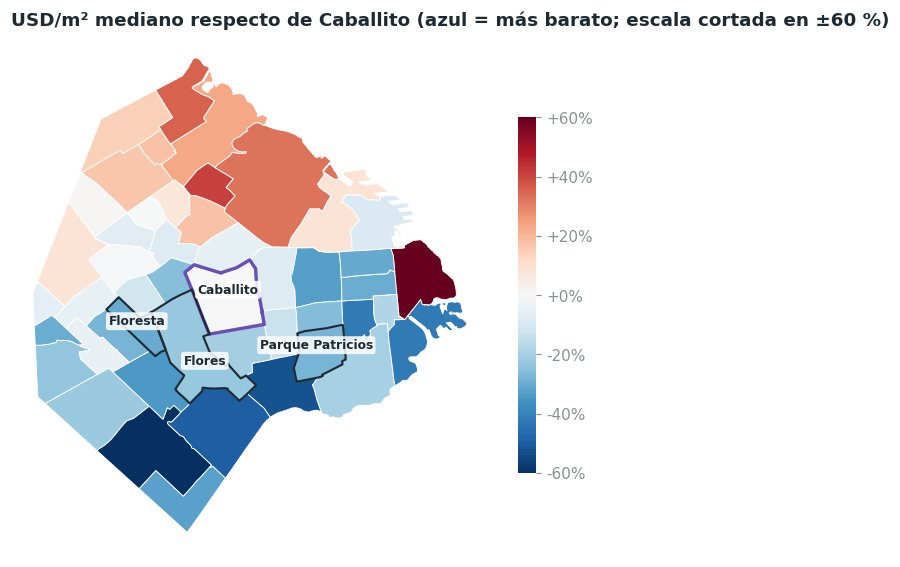

In [22]:
# Mapa de un ejemplo: diferencia de precio de cada barrio respecto de Caballito, con sus alternativas resaltadas.
base = 'Caballito'
rel = bx['usd_m2'] / bx.loc[base, 'usd_m2'] - 1
ax = mapa_barrios(rel, f'USD/m² mediano respecto de {base} (azul = más barato; escala cortada en ±60 %)', cmap='RdBu_r',
                  fmt=lambda x: f'{x:+.0%}', centro=0, lim=.6, etiquetas=0)
for b in [base] + [f['alternativa'] for f in alternativas(base)]:
    f = next(f for f in geo['features'] if f['properties']['barrio'] == b)
    g = f['geometry']
    anillo = np.array(g['coordinates'][0] if g['type'] == 'Polygon' else max(g['coordinates'], key=lambda p: len(p[0]))[0])
    ax.plot(anillo[:, 0], anillo[:, 1], color=JACARANDA if b == base else ASFALTO, lw=2.2 if b == base else 1.4)
    ax.annotate(b, anillo.mean(axis=0), ha='center', fontsize=8, fontweight='semibold',
                bbox=dict(boxstyle='round,pad=.2', fc='white', ec='none', alpha=.85))
plt.show()

**Lectura.** Para los barrios caros aparece al menos una alternativa con entorno parecido y entre 10 % y 35 % menos
de USD/m² (Palermo → Recoleta −18 %, Caballito −24 %; Caballito → Flores −23 %). Las alternativas no siempre son
limítrofes: el perfil de servicios cruza la ciudad. La columna "más distinto en" suele ser la gastronomía: la
alternativa más barata es, en general, más tranquila. Eso es justo lo que la persona necesita saber.

> **Para la app · comparación de barrios.** Al abrir un barrio, una sección *"Parecidos y más accesibles"* con
> 2 o 3 barrios, el porcentaje de diferencia en USD/m² y una línea por capa: *"Igual: subte a menos de 500 m,
> mucha gastronomía. Distinto: menos verde"*. Un clic aplica la misma búsqueda en el barrio sugerido.

## 7. Oportunidad de aviso: precio por debajo de sus comparables

Dos métodos independientes, para no depender de uno solo:

**A. Comparables robustos.** Para cada aviso, la mediana de USD/m² de los avisos del mismo barrio y ambientes y
una desviación robusta (MAD). Se mide cuántas desviaciones está por debajo (`z_comparables`).

**B. Modelo hedónico fuera de muestra.** Gradient boosting sobre log(USD/m²) con superficie, ambientes, barrio,
coordenadas, distancias a transporte/parque/hospital, gastronomía, escuelas y fuente. Cada aviso recibe la
predicción de un modelo que **no lo vio** (validación cruzada de 5 pliegues agrupada por `grupo`, para que un
posible duplicado entre fuentes no quede de los dos lados). Se mide la brecha `precio publicado / esperado − 1`.

Un aviso se marca como **oportunidad** si los dos métodos coinciden y la brecha supera el error típico del modelo.
Antes, se separan los avisos con **señales de error de carga**, que también parecen baratos.

In [23]:
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import GroupKFold

m = venta.copy()
m['barrio_code'] = m['neighborhood'].astype('category').cat.codes
m['agency_code'] = m['agency'].astype('category').cat.codes
feats = ['covered_area', 'total_area_m2', 'rooms', 'barrio_code', 'latitude', 'longitude', 'dist_transporte_m',
         'dist_parque_m', 'dist_hospital_m', 'gastronomia_500m', 'escuelas_500m', 'agency_code']
cat_idx = [feats.index('barrio_code'), feats.index('agency_code')]
y_log = np.log(m['precio_m2'])

oof = np.zeros(len(m))
for tr, te in GroupKFold(n_splits=5).split(m, groups=m['grupo']):
    mod = HistGradientBoostingRegressor(max_iter=500, learning_rate=.05, min_samples_leaf=20,
                                        categorical_features=cat_idx, random_state=42)
    mod.fit(m.iloc[tr][feats], y_log.iloc[tr])
    oof[te] = mod.predict(m.iloc[te][feats])

m['usd_m2_esperado'] = np.exp(oof)
m['brecha_modelo'] = m['precio_m2'] / m['usd_m2_esperado'] - 1
mae = (m['precio_m2'] - m['usd_m2_esperado']).abs().mean()
mdape = m['brecha_modelo'].abs().median()
print(f'Error fuera de muestra: MAE {mae:,.0f} USD/m² · error porcentual mediano {mdape:.1%}')
print('Cuantiles de la brecha:', m['brecha_modelo'].quantile([.05, .1, .25, .5, .75, .9, .95]).round(3).to_dict())

Error fuera de muestra: MAE 448 USD/m² · error porcentual mediano 12.9%
Cuantiles de la brecha: {0.05: -0.329, 0.1: -0.249, 0.25: -0.128, 0.5: 0.003, 0.75: 0.132, 0.9: 0.306, 0.95: 0.451}


In [24]:
g = m.groupby(['neighborhood', 'rooms'])['precio_m2']
m['n_comparables'] = g.transform('size') - 1
m['mediana_comparables'] = g.transform('median')
mad = g.transform(lambda s: (s - s.median()).abs().median())
m['z_comparables'] = (m['precio_m2'] - m['mediana_comparables']) / (1.4826 * mad.replace(0, np.nan))

# Señales de posible error de carga (no se descartan: se marcan para revisar).
p01 = m.groupby('neighborhood')['precio_m2'].transform(lambda s: s.quantile(.01))
m['revisar'] = ''
m.loc[m['ratio_cubierta'] < .5, 'revisar'] += 'cubierta < 50 % del total; '
m.loc[m['m2_por_ambiente'] < 12, 'revisar'] += 'menos de 12 m² por ambiente; '
m.loc[m['precio_m2'] < p01, 'revisar'] += 'USD/m² en el 1 % más bajo del barrio; '
m.loc[m['price'] < 25_000, 'revisar'] += 'precio < USD 25.000; '
med_m2 = m.groupby(['neighborhood', 'rooms'])['covered_area'].transform('median')
m.loc[m['covered_area'] > 2.5 * med_m2, 'revisar'] += 'superficie > 2,5 veces la de sus comparables; '
m['revisar'] = m['revisar'].str.rstrip('; ')

UMBRAL_BRECHA = -0.20          # más del doble del error porcentual mediano del modelo
UMBRAL_Z = -1.5               # además, claramente por debajo de la mediana de su barrio y ambientes
MIN_COMPARABLES = 10
m['oportunidad'] = ((m['brecha_modelo'] <= UMBRAL_BRECHA) & (m['z_comparables'] <= UMBRAL_Z) &
                    (m['n_comparables'] >= MIN_COMPARABLES) & (m['revisar'] == ''))
m['para_revisar'] = (m['brecha_modelo'] <= UMBRAL_BRECHA) & (m['revisar'] != '')
# Una misma propiedad publicada en dos fuentes cuenta una sola vez (columna grupo del modelo).
m['copia'] = m.duplicated('grupo') & m['oportunidad']
m.loc[m['copia'], 'oportunidad'] = False

print(f"Oportunidades: {m['oportunidad'].sum()} propiedades ({m['oportunidad'].mean():.1%} de los avisos); "
      f"{m['copia'].sum()} copias en otra fuente no se cuentan dos veces")
print(f"Parecen baratos pero tienen señales de error de carga: {m['para_revisar'].sum()}")
baratos = m[(m['brecha_modelo'] <= UMBRAL_BRECHA) & (m['revisar'] == '')]
print(f"De los avisos con brecha ≤ {UMBRAL_BRECHA:.0%} y sin señales de error, los comparables confirman "
      f"(z ≤ {UMBRAL_Z}) el {(baratos['z_comparables'] <= UMBRAL_Z).mean():.0%}")

Oportunidades: 76 propiedades (2.0% de los avisos); 5 copias en otra fuente no se cuentan dos veces
Parecen baratos pero tienen señales de error de carga: 68
De los avisos con brecha ≤ -20% y sin señales de error, los comparables confirman (z ≤ -1.5) el 19%


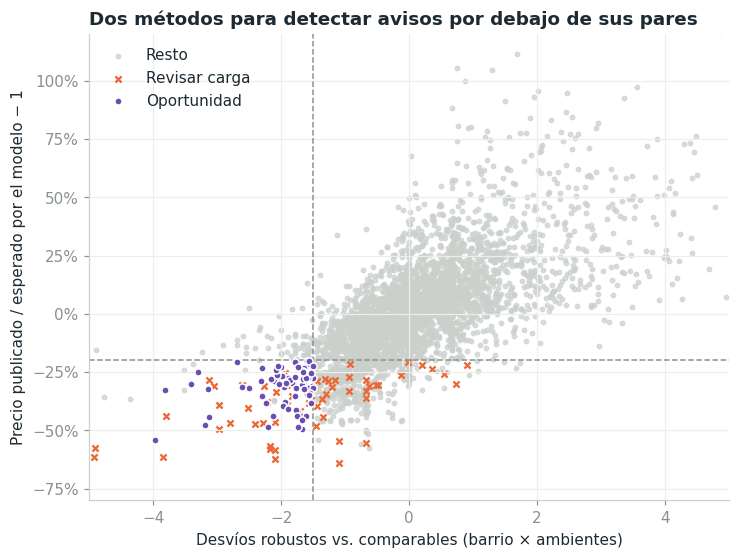

In [25]:
fig, ax = plt.subplots(figsize=(7.5, 5.5))
resto = m[~m['oportunidad'] & ~m['para_revisar']]
resto = resto[~resto['copia']]
ax.scatter(resto['z_comparables'], resto['brecha_modelo'], s=8, color=CORDON, alpha=.7, label='Resto', rasterized=True)
ax.scatter(m.loc[m['para_revisar'], 'z_comparables'], m.loc[m['para_revisar'], 'brecha_modelo'], s=16,
           color=NARANJA, marker='x', label='Revisar carga')
ax.scatter(m.loc[m['oportunidad'], 'z_comparables'], m.loc[m['oportunidad'], 'brecha_modelo'], s=22,
           color=JACARANDA, edgecolor='white', linewidth=1, label='Oportunidad', zorder=3)
ax.axhline(UMBRAL_BRECHA, color=GRIS, ls='--', lw=1); ax.axvline(UMBRAL_Z, color=GRIS, ls='--', lw=1)
ax.set_xlim(-5, 5); ax.set_ylim(-.8, 1.2)
ax.yaxis.set_major_formatter(pct)
ax.set_xlabel('Desvíos robustos vs. comparables (barrio × ambientes)')
ax.set_ylabel('Precio publicado / esperado por el modelo − 1')
ax.set_title('Dos métodos para detectar avisos por debajo de sus pares')
ax.legend(loc='upper left')
plt.show()

In [26]:
# ¿Las oportunidades se concentran en una fuente o un barrio? Si sí, puede ser un sesgo de carga y no del mercado.
por_fuente = pd.DataFrame({'avisos': m['agency'].value_counts(), 'oportunidades': m.groupby('agency')['oportunidad'].sum()})
por_fuente['tasa'] = por_fuente['oportunidades'] / por_fuente['avisos']
display(por_fuente.sort_values('avisos', ascending=False).style.format({'tasa': '{:.1%}'}))

por_barrio = m.groupby('neighborhood').agg(avisos=('id', 'size'), oportunidades=('oportunidad', 'sum'))
por_barrio['tasa'] = por_barrio['oportunidades'] / por_barrio['avisos']
display(por_barrio.sort_values('oportunidades', ascending=False).head(12).style.format({'tasa': '{:.1%}'}))

,avisos,oportunidades,tasa
agency,,,
zonaprop,2272,48,2.1%
remax,583,11,1.9%
century21,545,9,1.7%
migliorisi,388,8,2.1%
clarin,18,0,0.0%


,avisos,oportunidades,tasa
neighborhood,,,
Almagro,207,5,2.4%
Chacarita,58,5,8.6%
Recoleta,141,4,2.8%
Palermo,303,4,1.3%
Villa Ortúzar,56,4,7.1%
Flores,104,3,2.9%
Boedo,63,3,4.8%
Balvanera,132,3,2.3%
Saavedra,84,3,3.6%


In [27]:
cols_op = ['id', 'neighborhood', 'agency', 'price', 'covered_area', 'total_area_m2', 'rooms', 'precio_m2',
           'usd_m2_esperado', 'brecha_modelo', 'mediana_comparables', 'z_comparables', 'n_comparables', 'expenses', 'url']
if TIENE_EDIFICIO:
    cols_op[-1:-1] = ['age_years', 'condition']
oportunidades = m[m['oportunidad']].sort_values('brecha_modelo')[cols_op]
tabla_op = oportunidades.head(20).drop(columns='url')
formatos = {'price': '{:,.0f}', 'precio_m2': '{:,.0f}', 'usd_m2_esperado': '{:,.0f}', 'mediana_comparables': '{:,.0f}',
            'brecha_modelo': '{:+.0%}', 'z_comparables': '{:+.1f}', 'expenses': '{:,.0f}', 'age_years': '{:.0f}'}
display(tabla_op.style.format({k: v for k, v in formatos.items() if k in tabla_op}, na_rep='').hide(axis='index'))

oportunidades.to_csv(SALIDA / 'oportunidades_venta.csv', index=False)
m[m['para_revisar']][cols_op + ['revisar']].to_csv(SALIDA / 'avisos_para_revisar.csv', index=False)
print('Guardado en', SALIDA)

id,neighborhood,agency,price,covered_area,total_area_m2,rooms,precio_m2,usd_m2_esperado,brecha_modelo,mediana_comparables,z_comparables,n_comparables,expenses,age_years,condition
remax:421841012-147,Floresta,remax,"28,000",48.110000,59.440000,3,582,"1,268",-54%,"1,884",-4.0,21,,,
century21:388720,Palermo,century21,"95,000",50.000000,60.000000,2,"1,900","3,765",-50%,"3,372",-1.7,83,,70,excelente
zonaprop:60653535,San Nicolás,zonaprop,"68,000",64.000000,74.000000,2,"1,062","2,073",-49%,"1,853",-2.2,23,"281,850",44,
zonaprop:60659157,Balvanera,zonaprop,"48,000",43.000000,43.000000,1,"1,116","2,170",-49%,"2,387",-1.7,26,"185,000",63,
remax:421271036-130,Saavedra,remax,"80,000",41.630000,55.730000,2,"1,922","3,663",-48%,"2,936",-3.2,39,,,
zonaprop:60611286,La Paternal,zonaprop,"60,000",42.000000,42.000000,2,"1,429","2,620",-45%,"2,609",-1.7,18,"156,000",30,
zonaprop:60343072,Agronomía,zonaprop,"38,985",48.000000,57.000000,2,812,"1,458",-44%,"2,468",-3.1,18,,0,
century21:504012,Flores,century21,"54,000",42.000000,45.000000,2,"1,286","2,296",-44%,"2,258",-1.7,27,,66,bueno
migliorisi:a31134,Palermo,migliorisi,"92,000",47.000000,51.000000,2,"1,957","3,488",-44%,"3,372",-1.6,83,,50,
remax:421211043-209,Boedo,remax,"68,000",59.030000,74.360000,3,"1,152","2,045",-44%,"2,147",-1.8,23,,,


Guardado en ..\data\processed\eda-colab\salidas


### ¿Las oportunidades son edificios viejos o a reciclar?

Se vuelve a estimar el modelo sumando **antigüedad y estado** como variables (vacías donde la fuente no las
publica) y se compara, en el subconjunto que sí tiene antigüedad, cuántas oportunidades sobreviven.

In [28]:
if TIENE_EDIFICIO:
    m['cond_code'] = m['condition'].map({e: i for i, e in enumerate(ORDEN_ESTADO)})
    feats_ed = feats + ['age_years', 'cond_code']
    oof2 = np.zeros(len(m))
    for tr, te in GroupKFold(n_splits=5).split(m, groups=m['grupo']):
        mod = HistGradientBoostingRegressor(max_iter=500, learning_rate=.05, min_samples_leaf=20,
                                            categorical_features=cat_idx, random_state=42)
        mod.fit(m.iloc[tr][feats_ed], y_log.iloc[tr])
        oof2[te] = mod.predict(m.iloc[te][feats_ed])
    m['brecha_modelo_ed'] = m['precio_m2'] / np.exp(oof2) - 1
    sub = m[m['age_years'].notna()]
    mae1 = (sub['precio_m2'] - sub['usd_m2_esperado']).abs().mean()
    mae2 = (sub['precio_m2'] - np.exp(oof2[m['age_years'].notna().to_numpy()])).abs().mean()
    print(f'Avisos con antigüedad: {len(sub)} · MAE sin edificio {mae1:,.0f} → con edificio {mae2:,.0f} USD/m²')

    op_ed = ((sub['brecha_modelo_ed'] <= UMBRAL_BRECHA) & (sub['z_comparables'] <= UMBRAL_Z) &
             (sub['n_comparables'] >= MIN_COMPARABLES) & (sub['revisar'] == '') & ~sub['copia'])
    antes, despues = int(sub['oportunidad'].sum()), int(op_ed.sum())
    print(f'Oportunidades en ese subconjunto: {antes} sin edificio → {despues} con edificio '
          f'({despues - antes:+d}); siguen siendo oportunidad {int((sub["oportunidad"] & op_ed).sum())} de {antes}')
    comp = pd.DataFrame({
        'oportunidades': sub[sub['oportunidad']]['age_years'].describe()[['count', '25%', '50%', '75%']],
        'resto': sub[~sub['oportunidad']]['age_years'].describe()[['count', '25%', '50%', '75%']]})
    comp.index = ['avisos', 'antigüedad P25', 'antigüedad mediana', 'antigüedad P75']
    display(comp.style.format('{:.0f}'))
    est = pd.crosstab(sub['condition'], sub['oportunidad'], normalize='columns').reindex(
        [e for e in ORDEN_ESTADO if e in set(sub['condition'].dropna())])
    est.columns = ['resto', 'oportunidades'][:len(est.columns)]
    display(est.style.format('{:.0%}'))

Avisos con antigüedad: 2937 · MAE sin edificio 443 → con edificio 381 USD/m²
Oportunidades en ese subconjunto: 63 sin edificio → 42 con edificio (-21); siguen siendo oportunidad 37 de 63


,oportunidades,resto
avisos,63,2874
antigüedad P25,40,0
antigüedad mediana,46,16
antigüedad P75,56,46


,resto,oportunidades
condition,,
a estrenar,33%,0%
en construcción,12%,11%
excelente,17%,22%
muy bueno,24%,11%
bueno,10%,56%
reciclado,2%,0%
a reciclar,2%,0%


**Lectura.** En los 2.937 avisos con antigüedad (todas las fuentes salvo RE/MAX), sumar antigüedad y estado al
modelo **baja el error de 443 a 381 USD/m² (−14 %)**: es la mejora más grande que se consiguió con cualquier
variable. Y cambia las oportunidades:
- **De 63 oportunidades en ese subconjunto, 26 dejan de serlo** al tener en cuenta el edificio (y aparecen 5
  nuevas: quedan 42). No eran avisos baratos: eran edificios viejos comparados con avisos nuevos.
- Las oportunidades sin control de edificio tenían una antigüedad mediana de **46 años, contra 16 del resto**.
  En las de Century 21, el 56 % se declaraba en estado "bueno" (contra 10 % del resto).
- 7 declaran 0 años. Una es de Century 21 y está en construcción (de pozo, que suele pedir menos). Las otras 6
  son de Zonaprop, y algunas piden precios difíciles de creer para algo a estrenar (unos USD 810/m² en
  Agronomía): es probable que sea el 0 por defecto. Conviene marcarlas para revisar.
- **Para la alerta:** 4 de cada 10 oportunidades se explicaban por la antigüedad. Con el dato disponible para
  el 77 % de la base, el criterio de oportunidad tiene que usarlo. RE/MAX (15 % de la base) sigue sin dato.

In [29]:
# Sensibilidad: cuántas oportunidades quedan según el umbral. Sirve para elegir el corte de la alerta.
umbrales = [-.10, -.15, -.20, -.25, -.30, -.35]
sens = pd.DataFrame([{'umbral_brecha': u,
                      'oportunidades': int(((m['brecha_modelo'] <= u) & (m['z_comparables'] <= UMBRAL_Z) &
                                            (m['n_comparables'] >= MIN_COMPARABLES) & (m['revisar'] == '')
                                            & ~m.duplicated('grupo')).sum())}
                     for u in umbrales])
sens['por_100_avisos'] = sens['oportunidades'] / len(m) * 100
display(sens.style.format({'umbral_brecha': '{:.0%}', 'por_100_avisos': '{:.1f}'}).hide(axis='index'))

umbral_brecha,oportunidades,por_100_avisos
-10%,108,2.8
-15%,92,2.4
-20%,76,2.0
-25%,57,1.5
-30%,37,1.0
-35%,20,0.5


**Lectura.**
- El modelo comete un error porcentual mediano del 13 % fuera de muestra (MAE ≈ 450 USD/m², en línea con el
  modelo del capstone). Una brecha de −10 % no se distingue del ruido; con −20 % el aviso queda en el 15 % más
  barato respecto de lo esperado.
- Con los dos criterios juntos (modelo ≤ −20 % y comparables ≤ −1,5 desvíos) quedan **76 propiedades, el 2 % de
  los avisos**. La tabla de sensibilidad muestra cuántas habría con otros cortes (de 108 con −10 % a 20 con −35 %):
  sirve para elegir cuántas alertas por semana son razonables.
- **Los dos métodos no ven lo mismo.** De los avisos que el modelo ve ≥20 % baratos, solo 1 de cada 5 también está
  claramente por debajo de la mediana de su barrio y ambientes. El modelo descuenta tamaño, proporción cubierta y
  ubicación fina; los comparables no. Exigir los dos deja los casos más robustos.
- Los avisos "muy baratos" con **señales de error de carga** (m² cubiertos mal informados, superficie atípica,
  precio en el 1 % más bajo del barrio) se separan (68 avisos): una alerta falsa le quita credibilidad a todas.
  Aun así, el primer caso de la tabla (un 3 ambientes de 48 m² a USD 28.000 en Floresta, publicado por RE/MAX y
  Zonaprop) es el tipo de aviso que conviene verificar antes de alertar.
- Las oportunidades se reparten de forma parecida entre fuentes (Zonaprop, RE/MAX, Century 21, Migliorisi), así
  que no parecen un artefacto de una sola fuente.
- **Lo que este modelo no ve:** la antigüedad y el estado (el control de más abajo los suma y muestra cuánto
  cambia la lista); orientación, luminosidad y amenities no están en la base. Un aviso barato puede estar a
  reciclar. Por eso la etiqueta tiene que decir *"por debajo de avisos comparables"*, no *"ganga"*.

> **Para la app · alertas.** (1) Priorizar en el correo de Make los avisos nuevos con brecha ≤ −20 % y la frase
> *"pide 24 % menos por m² que avisos parecidos del barrio (mediana USD 2.450/m², 31 comparables)"*.
> (2) Una opción en la búsqueda guardada: *"avisarme solo si está por debajo de sus comparables"*.
> (3) Validar con la inmobiliaria (protocolo de `docs/validacion-inmobiliaria.md`) una muestra de estas
> oportunidades: ¿cuántas son reales y cuántas tienen un motivo (estado, error de carga)?

## 8. Alquiler: dos mercados y la relación precio/alquiler

La base de alquiler tiene avisos en pesos y en dólares. Primero se ve si son el mismo mercado.

> **Supuesto a completar:** `TC_ARS_POR_USD` es el tipo de cambio para convertir alquileres en pesos. **Poner el
> valor del día de la captura** (8 de noviembre de 2026). Los resultados se muestran también para un rango de
> tipos de cambio, para ver cuánto dependen de este supuesto.

In [30]:
TC_ARS_POR_USD = 1450.0   # SUPUESTO: reemplazar por el tipo de cambio del día de la captura.

alquiler['precio_m2'] = alquiler['price'] / alquiler['covered_area']
alquiler['precio_usd'] = np.where(alquiler['currency'] == 'USD', alquiler['price'], alquiler['price'] / TC_ARS_POR_USD)
alquiler['usd_m2'] = alquiler['precio_usd'] / alquiler['covered_area']

resumen_moneda = alquiler.groupby('currency').agg(avisos=('id', 'size'), m2_medianos=('covered_area', 'median'),
                                                  usd_m2_mediano=('usd_m2', 'median'),
                                                  pct_puerto_madero=('neighborhood', lambda s: (s == 'Puerto Madero').mean()))
display(resumen_moneda.style.format({'usd_m2_mediano': '{:.1f}', 'pct_puerto_madero': '{:.0%}', 'm2_medianos': '{:.0f}'}))
display(pd.crosstab(alquiler['agency'], alquiler['currency']))

# Mismo barrio, distinta moneda: ¿los publicados en USD piden más por m²?
pares = alquiler.groupby(['neighborhood', 'currency'])['usd_m2'].median().unstack().dropna()
cnt = alquiler.groupby(['neighborhood', 'currency']).size().unstack().fillna(0)
pares = pares[(cnt.loc[pares.index, 'USD'] >= 5) & (cnt.loc[pares.index, 'ARS'] >= 5)]
print(f"Barrios con ≥5 avisos en cada moneda: {len(pares)} · USD/ARS mediano del USD/m²: {(pares['USD'] / pares['ARS']).median():.2f}")

,avisos,m2_medianos,usd_m2_mediano,pct_puerto_madero
currency,,,,
ARS,2570,40,13.0,0%
USD,702,65,18.8,15%


currency,ARS,USD
agency,,
century21,219,109
migliorisi,42,3
mob,503,332
remax,9,13
zonaprop,1797,245


Barrios con ≥5 avisos en cada moneda: 22 · USD/ARS mediano del USD/m²: 1.25


,años (mediana entre barrios)
1200,12.3
1350,13.8
1450,14.9
1600,16.4
1800,18.5


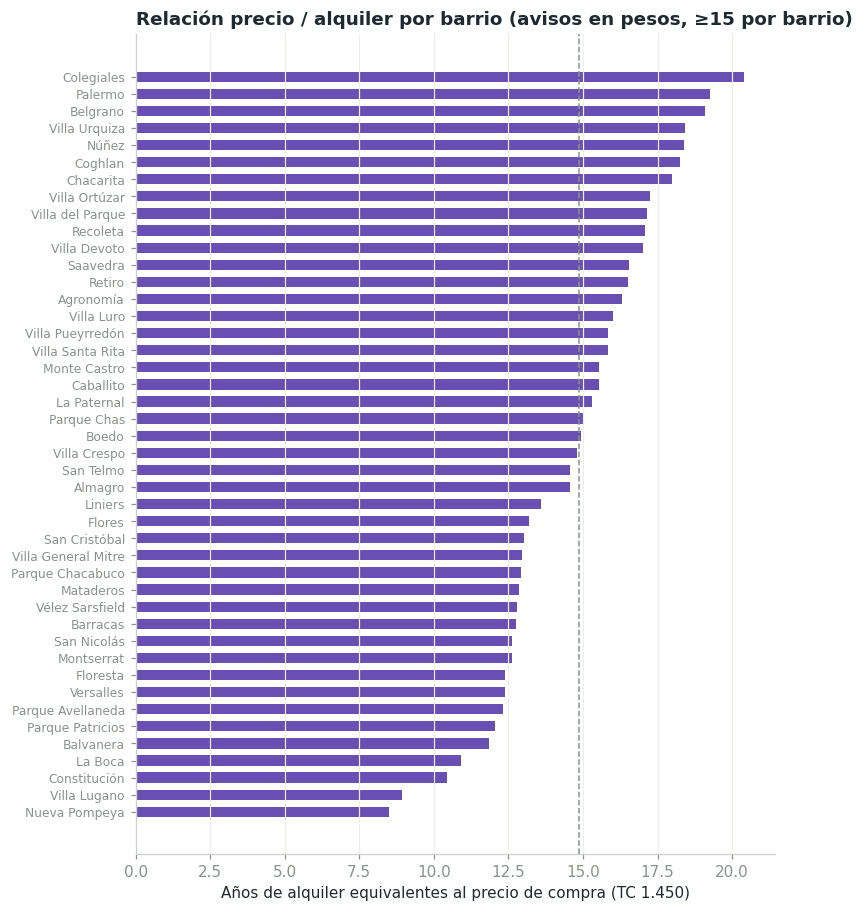

In [31]:
ars = alquiler[alquiler['currency'] == 'ARS']
alq_b = ars.groupby('neighborhood').agg(n_alq=('id', 'size'), ars_m2_mes=('precio_m2', 'median'),
                                        alquiler_mediano_ars=('price', 'median'))
alq_b = alq_b[alq_b['n_alq'] >= 15]
pr = barrios[['usd_m2', 'avisos']].join(alq_b, how='inner')

def anios_de_alquiler(tc):
    # Años de alquiler (en pesos, convertido) que equivalen al precio de compra del mismo m².
    return pr['usd_m2'] / (pr['ars_m2_mes'] / tc * 12)

pr['anios_alquiler'] = anios_de_alquiler(TC_ARS_POR_USD)
pr['rendimiento_bruto'] = 1 / pr['anios_alquiler']
sens_tc = pd.DataFrame({tc: anios_de_alquiler(tc).median() for tc in (1200, 1350, 1450, 1600, 1800)}, index=['años (mediana entre barrios)']).T
display(sens_tc.style.format('{:.1f}'))

pr = pr.sort_values('anios_alquiler')
fig, ax = plt.subplots(figsize=(7.5, max(4, .22 * len(pr))))
ax.barh(pr.index, pr['anios_alquiler'], color=JACARANDA, height=.6)
ax.axvline(pr['anios_alquiler'].median(), color=GRIS, ls='--', lw=1)
ax.set_xlabel(f'Años de alquiler equivalentes al precio de compra (TC {miles(TC_ARS_POR_USD)})')
ax.set_title('Relación precio / alquiler por barrio (avisos en pesos, ≥15 por barrio)')
ax.tick_params(axis='y', labelsize=8); ax.grid(axis='y', visible=False)
plt.show()

**Lectura.**
- Los alquileres en dólares **son otro segmento**: se concentran en Puerto Madero y en el corredor norte, son más
  grandes (65 m² medianos contra 40) y, con el tipo de cambio supuesto, piden alrededor de 25 % más por m² que los
  publicados en pesos del mismo barrio (temporarios, amueblados, categoría). Esa brecha depende del tipo de cambio.
  Mezclarlos distorsiona cualquier comparación.
- Con el tipo de cambio supuesto, comprar equivale a unos 15 años de alquiler en la mediana de los barrios
  (rendimiento bruto cercano al 7 %), entre 12 y 18 años según el tipo de cambio.
- El patrón es norte–sur: en Colegiales, Palermo y Belgrano comprar equivale a 19–20 años de alquiler; en
  Nueva Pompeya y Villa Lugano, a unos 9. Los barrios caros son caros también en relación con su alquiler.
- La relación precio/alquiler varía bastante entre barrios: donde los años de alquiler son menos, comprar "rinde"
  más como inversión, y donde son más, alquilar es relativamente barato frente a comprar. La conclusión depende
  del tipo de cambio, por eso la tabla de sensibilidad.

> **Para la app · Comprar / Alquilar.** (1) En la ficha del barrio, una línea *"Comprar acá equivale a ~X años de
> alquiler"* (con el tipo de cambio y la fecha visibles). Ayuda a quien duda entre alquilar y comprar y a quien
> compra para alquilar. (2) Separar siempre las búsquedas por moneda, como ya hace la app: el análisis confirma
> que son segmentos distintos, no solo una cuestión de conversión.

## 9. El mismo departamento, ¿a distinto precio?

El modelo agrupa como *posibles duplicados* los avisos de fuentes distintas con mismo barrio, ambientes, m² y
precio redondeado. Acá se relaja el criterio de precio para ver **si una misma propiedad aparece publicada con
precios distintos** en dos fuentes (mismo barrio, ambientes, m² cubiertos y totales, y pines a menos de 150 m
cuando ambos tienen pin).

In [32]:
def km(lat1, lon1, lat2, lon2):
    p = np.pi / 180
    a = np.sin((lat2 - lat1) * p / 2) ** 2 + np.cos(lat1 * p) * np.cos(lat2 * p) * np.sin((lon2 - lon1) * p / 2) ** 2
    return 12742 * np.arcsin(np.sqrt(a))

clave = ['neighborhood', 'rooms', 'covered_area', 'total_area_m2']
c = venta.dropna(subset=['total_area_m2']).copy()
pares = c.merge(c, on=clave, suffixes=('_a', '_b'))
pares = pares[pares['agency_a'] < pares['agency_b']]
pares['dist_m'] = km(pares['latitude_a'], pares['longitude_a'], pares['latitude_b'], pares['longitude_b']) * 1000
pares = pares[pares['dist_m'].isna() | (pares['dist_m'] <= 150)]
pares['dif_precio'] = (pares[['price_a', 'price_b']].max(axis=1) / pares[['price_a', 'price_b']].min(axis=1)) - 1
# Si un aviso ya tiene una copia con el mismo precio en la otra fuente, sus otros pares son unidades distintas
# del mismo edificio (p. ej., dos 2 ambientes iguales a USD 86.000 y 96.000), no la misma propiedad.
exactos = pares[pares['dif_precio'] <= .01]
con_copia = set(exactos['id_a']) | set(exactos['id_b'])
pares = pares[(pares['dif_precio'] <= .01) | (~pares['id_a'].isin(con_copia) & ~pares['id_b'].isin(con_copia))]

print(f'Pares candidatos entre fuentes: {len(pares)}')
print(f"Con el mismo precio (±1 %): {(pares['dif_precio'] <= .01).sum()} · "
      f"con diferencia de 1 % a 15 %: {pares['dif_precio'].between(.01, .15, inclusive='right').sum()} · "
      f"más de 15 % (probablemente otra unidad): {(pares['dif_precio'] > .15).sum()}")
dif = pares[pares['dif_precio'].between(.01, .15, inclusive='right')].sort_values('dif_precio', ascending=False)
display(dif[['neighborhood', 'rooms', 'covered_area', 'agency_a', 'price_a', 'agency_b', 'price_b', 'dif_precio', 'dist_m']]
        .head(10).style.format({'price_a': '{:,.0f}', 'price_b': '{:,.0f}', 'dif_precio': '{:+.1%}', 'dist_m': '{:.0f}'}).hide(axis='index'))

Pares candidatos entre fuentes: 123
Con el mismo precio (±1 %): 88 · con diferencia de 1 % a 15 %: 9 · más de 15 % (probablemente otra unidad): 26


neighborhood,rooms,covered_area,agency_a,price_a,agency_b,price_b,dif_precio,dist_m
Villa Crespo,1,29.000000,migliorisi,"79,900",zonaprop,"89,000",+11.4%,nan
San Nicolás,1,22.000000,century21,"53,000",zonaprop,"59,000",+11.3%,127
Villa Crespo,1,29.000000,migliorisi,"97,865",zonaprop,"89,000",+10.0%,nan
Villa Crespo,3,62.000000,migliorisi,"130,000",zonaprop,"120,000",+8.3%,nan
Villa Crespo,2,32.000000,migliorisi,"63,500",zonaprop,"59,900",+6.0%,nan
Almagro,1,27.000000,migliorisi,"67,000",zonaprop,"69,900",+4.3%,nan
Villa Crespo,2,33.000000,migliorisi,"70,000",zonaprop,"67,500",+3.7%,nan
Balvanera,3,50.000000,migliorisi,"82,000",zonaprop,"80,000",+2.5%,nan
Balvanera,1,23.000000,migliorisi,"55,700",zonaprop,"55,000",+1.3%,nan


**Lectura.** La mayoría de los pares coincide en precio: son la misma propiedad publicada por una inmobiliaria
y en Zonaprop. Un grupo chico difiere en algunos puntos porcentuales; puede ser la misma unidad con el precio
desactualizado en una fuente, o dos unidades iguales del mismo edificio. Sin dirección no se puede saber, así
que la app debería decir "posible".

> **Para la app · aviso.** Agrupar los posibles duplicados en una sola tarjeta (*"también publicado en Zonaprop"*)
> y, si el precio difiere, mostrarlo: *"en otra fuente figura USD 4.000 menos"*. Evita alertas repetidas por la
> misma propiedad.

## 10. Síntesis: del EDA a la app

In [33]:
resumen = pd.DataFrame([
    ('Preferencias', 'La oferta crece a escalones con el presupuesto', 'Sugerir “con USD X más se suman N barrios”', '§4'),
    ('Comparación', 'La mediana del barrio es inestable con muestras chicas y hay mucha dispersión interna', 'Mostrar P25–P75 y una nota de confianza de la muestra', '§1–2'),
    ('Comparación', 'Hay barrios con entorno parecido y 10–35 % menos de USD/m²', 'Sección “Parecidos y más accesibles”, descrita capa por capa', '§6'),
    ('Comparación', 'Dentro del barrio, proporción descubierta, tamaño y ambientes mueven el USD/m²; la ubicación fina casi no', 'Comparar contra avisos de tamaño parecido; mostrar m² descubiertos', '§3'),
    ('Preferencias / comparación', 'La antigüedad es lo que más mueve el USD/m² dentro del barrio (rho −0,51): hasta 10 años +16 %, más de 30 años −13 a −15 %', 'Filtro de antigüedad y comparar contra avisos de antigüedad parecida', '§3 bis'),
    ('Comparación', 'Expensas faltan en >50 % y varían mucho', 'Mostrar costo mensual o “expensas no informadas”', '§3'),
    ('Mapa', 'El total de delitos sigue a la actividad urbana, no al precio', 'Delitos como contexto con tipo y franja; nunca para ordenar', '§5'),
    ('Búsqueda / alerta', '76 propiedades (2 %) quedan ≥20 % por debajo de lo esperado y de sus comparables', 'Alertas priorizadas y filtro “solo por debajo de comparables”', '§7'),
    ('Búsqueda / alerta', 'Con antigüedad, 26 de 63 oportunidades dejan de serlo: eran edificios viejos', 'Incluir la antigüedad en el criterio de la alerta', '§7'),
    ('Búsqueda / alerta', 'Parte de los “baratos” son errores de carga', 'Excluirlos de la alerta o marcarlos para revisar', '§7'),
    ('Comprar / Alquilar', 'Alquileres en USD son otro segmento; la relación precio/alquiler varía por barrio', '“Comprar acá equivale a X años de alquiler”', '§8'),
    ('Aviso', 'Hay posibles duplicados entre fuentes con precios distintos', 'Agrupar duplicados y mostrar la diferencia de precio', '§9'),
], columns=['paso del flujo', 'hallazgo', 'propuesta para la app', 'sección'])
display(resumen.style.hide(axis='index').set_properties(**{'text-align': 'left'}))

barrios.join(ent).to_csv(SALIDA / 'barrios_eda.csv')
alt.to_csv(SALIDA / 'barrios_alternativos.csv', index=False)
print('Tablas para la app guardadas en', SALIDA.resolve())

paso del flujo,hallazgo,propuesta para la app,sección
Preferencias,La oferta crece a escalones con el presupuesto,Sugerir “con USD X más se suman N barrios”,§4
Comparación,La mediana del barrio es inestable con muestras chicas y hay mucha dispersión interna,Mostrar P25–P75 y una nota de confianza de la muestra,§1–2
Comparación,Hay barrios con entorno parecido y 10–35 % menos de USD/m²,"Sección “Parecidos y más accesibles”, descrita capa por capa",§6
Comparación,"Dentro del barrio, proporción descubierta, tamaño y ambientes mueven el USD/m²; la ubicación fina casi no",Comparar contra avisos de tamaño parecido; mostrar m² descubiertos,§3
Preferencias / comparación,"La antigüedad es lo que más mueve el USD/m² dentro del barrio (rho −0,51): hasta 10 años +16 %, más de 30 años −13 a −15 %",Filtro de antigüedad y comparar contra avisos de antigüedad parecida,§3 bis
Comparación,Expensas faltan en >50 % y varían mucho,Mostrar costo mensual o “expensas no informadas”,§3
Mapa,"El total de delitos sigue a la actividad urbana, no al precio",Delitos como contexto con tipo y franja; nunca para ordenar,§5
Búsqueda / alerta,76 propiedades (2 %) quedan ≥20 % por debajo de lo esperado y de sus comparables,Alertas priorizadas y filtro “solo por debajo de comparables”,§7
Búsqueda / alerta,"Con antigüedad, 26 de 63 oportunidades dejan de serlo: eran edificios viejos",Incluir la antigüedad en el criterio de la alerta,§7
Búsqueda / alerta,Parte de los “baratos” son errores de carga,Excluirlos de la alerta o marcarlos para revisar,§7


Tablas para la app guardadas en C:\Users\Usuario\OneDrive\Escritorio\precio-entorno-caba\data\processed\eda-colab\salidas


### Datos que harían falta para el siguiente nivel

- **Historia de cada aviso:** guardar `primera_vez_visto` y `ultima_vez_visto` en cada actualización programada
  (ya corre cada 2 días). Con eso se mide **tiempo publicado** y **bajas de precio**, dos señales de oportunidad
  mucho más fuertes que el precio de una sola captura.
- **Antigüedad de RE/MAX y estado de Zonaprop:** la antigüedad ya está para el 77 % de la base. Falta RE/MAX,
  que no la publica en su búsqueda (habría que leer cada ficha), y el estado fuera de Century 21.
  Las próximas capturas de Zonaprop ya guardan la antigüedad.
- **Validación con la inmobiliaria:** revisar una muestra de las oportunidades de la sección 7 para estimar
  cuántas son reales.

*Precios de publicación, no tasaciones ni precios de cierre. Delitos: hechos registrados del Mapa del Delito de
CABA por barrio, 2024–2025.*